# TopoPyScale in the Pyrenees: a North–South transect

**Workshop demo**: downscaling ERA5 (2019–2020) across the whole Pyrenees, from the Ebro basin (Huesca) to the
Béarn piedmont (Pau), with [TopoPyScale](https://github.com/ArcticSnow/TopoPyScale).

TopoPyScale turns coarse reanalysis (here ERA5, ~31 km) into hillslope-scale meteorological forcing using a DEM:

* **3-D interpolation**: horizontal inverse-distance weighting between ERA5 cells + vertical interpolation in the
  *pressure-level* profiles (T, humidity, wind) to the real elevation of each point; pressure is recomputed
  hypsometrically.
* **Terrain-aware radiation**: shortwave split into direct/diffuse, then corrected for slope/aspect
  (illumination angle), cast shadows (horizon angles) and sky-view factor; longwave corrected for sky-view and
  terrain emission.
* **TopoSUB**: instead of computing every DEM pixel, pixels are clustered by (x, y, elevation, slope, aspect,
  sky-view) and only the cluster centroids are downscaled; results are mapped back to the grid.

What we will show along a ~30 km wide transect that contains two ERA5 grid columns:

1. the **long-distance N–S gradient** (Atlantic-influenced north vs Mediterranean/continental south),
2. the **elevation gradient** that ERA5 cannot resolve,
3. the **aspect / terrain gradient of shortwave radiation**,
4. a **validation against the Izas AWS** (2080 m, Spanish Pyrenees), and
5. a **snow simulation** (FSM) driven by the downscaled forcing, compared with the station snow depth.

> **Data note.** The ERA5 files provided for the workshop are **6-hourly** (00, 06, 12, 18 UTC). Radiation and
> precipitation are the 1-hour accumulations ending at those times. We downscale at this native 6-hourly step,
> so SW values are *1-hour means at 4 times of the day*, not daily means.

## 1. Setup

Switches: `MODE = 'light'` (workshop, ~300 clusters) or `'full'` (more clusters). Both use the same **30 m DEM**.
Results already on disk are re-used, so re-running the notebook is fast.

In [1]:
import contextlib
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from matplotlib.patches import Polygon, Rectangle

from TopoPyScale import topoclass as tc
import pyr_utils as pu

MODE = os.environ.get("TPS_MODE", "light")                 # 'light' or 'full'
N_CLUSTERS = {"light": 300, "full": 1500}[MODE]
CPU_CORES = int(os.environ.get("TPS_CORES", min(8, os.cpu_count())))
RUN_FSM = True
DEM_RES = 30.0                                             # m, both modes

CODE_DIR = Path.cwd()
LINKS = pu.load_links()                                    # private workshop links: data_links.yml (not in git)
DATA_ROOT = Path(os.environ.get("TPS_PYR_DATA") or LINKS.get("data_root") or CODE_DIR / "data")
CLIM = DATA_ROOT / "era5_topopyscale"                      # ERA5 re-formatted for TopoPyScale
PROJ_T = DATA_ROOT / f"transect_{MODE}"                    # TopoSUB project (transect)
PROJ_I = DATA_ROOT / "izas"                                # points project (Izas)
FSM_EXEC = CODE_DIR / "FSM" / "FSM"

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})
TIMES = {}


@contextlib.contextmanager
def timed(label):
    t0 = time.perf_counter()
    yield
    TIMES[label] = time.perf_counter() - t0
    print(f"[{label}] {TIMES[label] / 60:.1f} min")


print(f"MODE={MODE}  N_CLUSTERS={N_CLUSTERS}  CPU_CORES={CPU_CORES}")

MODE=light  N_CLUSTERS=300  CPU_CORES=8


## 2. Data

* **ERA5** (provided zip): daily `dSURF_*.nc` (z, t2m, d2m, sp, ssrd, strd, tp) and `dPLEV_*.nc`
  (z, t, u, v, q, r on 1000–600 hPa), i.e. the daily files TopoPyScale's `get_era5()` downloads from CDS.
  As in TopoPyScale's workflow we merge them into yearly `SURF_YYYY.nc` / `PLEV_YYYY.nc` (rename
  `valid_time`→`time`, `pressure_level`→`level`, crop around the Pyrenees), check that radiation is indeed a
  1-hour accumulation, and convert them to a **zarr store** (`ERA5.zarr`), which makes the downscaling >10× faster.
* **Izas AWS** (IPE-CSIC): 10-min data 2019–2021, UTC.
* **DEM**: Copernicus GLO-30 (2 tiles).

In [2]:
with timed("download + ERA5 preparation"):
    paths = pu.download_inputs(DATA_ROOT / "raw", LINKS)
    era5_info = pu.prepare_era5(paths["era5_daily"], CLIM)   # daily files -> yearly SURF_/PLEV_ + checks
    print("zarr store:", pu.build_zarr(CLIM).name)          # yearly files -> ERA5.zarr (fast downscaling)

  found ERA5_Pyr_2019_2020.zip
  found Izas_Meteo_2019-2021.xlsx
  found Copernicus_DSM_COG_10_N42_00_W001_00_DEM.tif
  found Copernicus_DSM_COG_10_N43_00_W001_00_DEM.tif
  found SURF_2019.nc, PLEV_2019.nc
  found SURF_2020.nc, PLEV_2020.nc


  ERA5 checks passed: {'n_times': 2924, 'lat': (41.62, 43.87), 'lon': (-1.560733333333332, 0.689566666666668), 'levels': [600.0, 650.0, 700.0, 750.0, 800.0, 850.0, 900.0, 950.0, 1000.0], 'ssrd_max_Wm2': 1002.9161111111111, 'tp_max_mm_per_h': 12.331008911132812}
zarr store: ERA5.zarr
[download + ERA5 preparation] 0.0 min


## 3. The transect and what ERA5 "sees"

The transect is a UTM rectangle **30 km wide**, centred between the two ERA5 grid columns at 0.561°W and 0.311°W,
from **42.10°N (Huesca)** to **43.35°N (Pau)**. The DEM gets an extra 10 km buffer so that horizon angles and
sky-view factors near the edges see the surrounding mountains; only the transect itself is clustered/downscaled.

  dem_transect_30m.tif: 5294 x 1667 px (8.8 Mpx) at 30 m, elevation 70-3237 m
[DEM preparation] 0.0 min


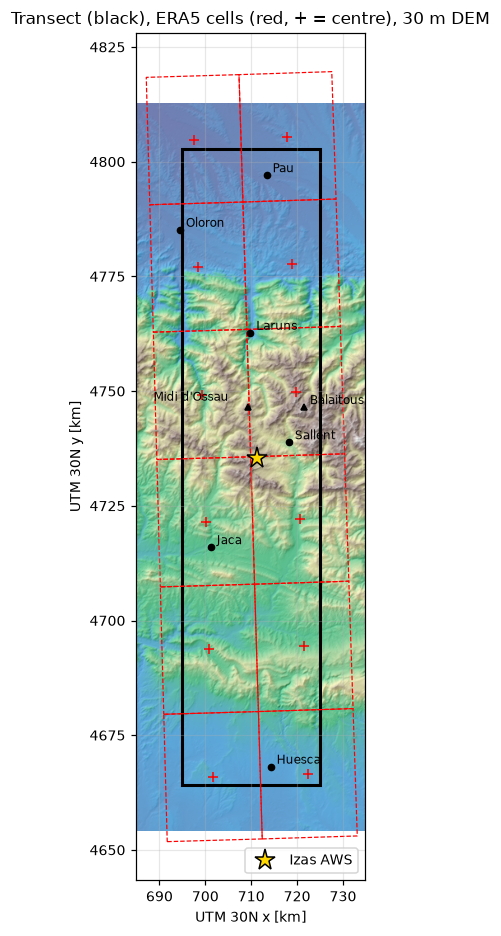

In [3]:
tb, db = pu.transect_bounds(res=DEM_RES, buffer_km=10)
DEM_FILE = DATA_ROOT / "dem" / "dem_transect_30m.tif"
MASK_FILE = DATA_ROOT / "dem" / "transect_mask.tif"
with timed("DEM preparation"):
    dem = pu.build_dem(paths["dem_tiles"], DEM_FILE, db, res=DEM_RES, mask_tif=MASK_FILE, mask_bounds=tb)

x_izas, y_izas = pu.to_utm.transform(pu.IZAS["lon"], pu.IZAS["lat"])
surf0 = pu.open_era5_surf(CLIM).isel(time=0).load()
oro = surf0.z / pu.G


def km(v):
    return np.asarray(v) / 1000.0


def era5_cells_in(bounds):
    """ERA5 cell centres (lat, lon) whose centre lies within the UTM bounds."""
    out = []
    for la in oro.latitude.values:
        for lo in oro.longitude.values:
            x, y = pu.to_utm.transform(lo, la)
            if bounds[0] < x < bounds[2] and bounds[1] < y < bounds[3]:
                out.append((la, lo))
    return out


def draw_era5_cells(ax, cells, **kw):
    for la, lo in cells:
        corners = [(lo - .125, la - .125), (lo + .125, la - .125), (lo + .125, la + .125), (lo - .125, la + .125)]
        xy = np.array([pu.to_utm.transform(a, b) for a, b in corners]) / 1000
        ax.add_patch(Polygon(xy, fill=False, **kw))
        x, y = pu.to_utm.transform(lo, la)
        ax.plot(x / 1000, y / 1000, "r+", ms=7)


def base_map(ax, stride=6, bounds=None, alpha=0.5, terrain=True):
    d = dem if bounds is None else dem.sel(x=slice(bounds[0], bounds[2]), y=slice(bounds[3], bounds[1]))
    d = d[::stride, ::stride]
    ext = [km(d.x[0]), km(d.x[-1]), km(d.y[-1]), km(d.y[0])]
    ax.imshow(pu.hillshade(d.values, DEM_RES * stride), cmap="gray", extent=ext)
    if terrain:
        ax.imshow(d.values, cmap="terrain", vmin=0, vmax=3200, alpha=alpha, extent=ext)
    return ext


cells = era5_cells_in(db)
fig, ax = plt.subplots(figsize=(6, 10))
base_map(ax)
ax.add_patch(Rectangle((km(tb[0]), km(tb[1])), km(tb[2] - tb[0]), km(tb[3] - tb[1]), fill=False, ec="k", lw=2))
draw_era5_cells(ax, cells, ec="r", lw=0.8, ls="--")
for name, (la, lo) in pu.PLACES.items():
    x, y = pu.to_utm.transform(lo, la)
    ax.plot(km(x), km(y), "k^" if name in ("Balaitous", "Midi d'Ossau") else "ko", ms=4)
    off = (-62, 4) if name == "Midi d'Ossau" else (4, 2)          # keep the two summit labels apart
    ax.annotate(name, (km(x), km(y)), xytext=off, textcoords="offset points", fontsize=8)
ax.plot(km(x_izas), km(y_izas), "*", color="gold", mec="k", ms=14, label="Izas AWS")
ax.set(xlabel="UTM 30N x [km]", ylabel="UTM 30N y [km]",
       title="Transect (black), ERA5 cells (red, + = centre), 30 m DEM")
ax.legend(loc="lower right")
plt.show()

### ERA5 orography vs the real terrain

ERA5's orography is a smoothed version of the terrain. Along our transect it never exceeds ~1400 m, while the real
summits (Balaitous, Midi d'Ossau) reach ~3000 m and the valley floors are much lower than ERA5's surface. Every
variable that depends on elevation (temperature, pressure, humidity, snow vs rain…) is affected.

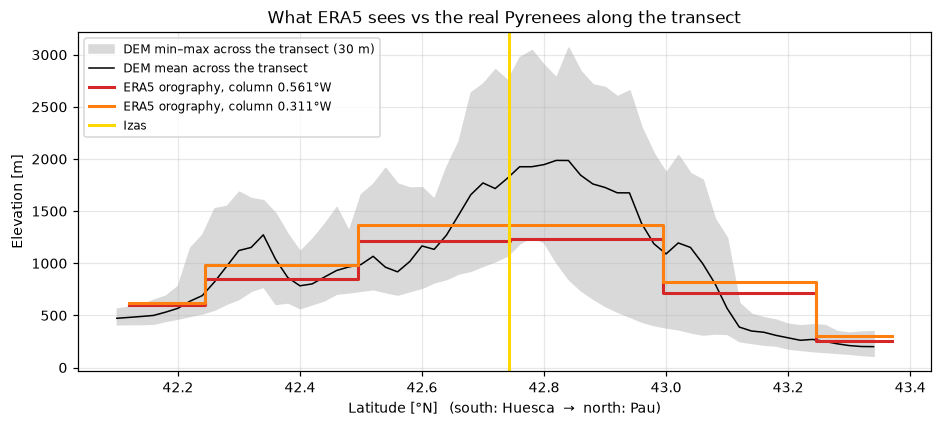

In [4]:
inside = dem.sel(x=slice(tb[0], tb[2]), y=slice(tb[3], tb[1]))
lat_rows = pu.to_ll.transform(np.full(inside.y.size, float(inside.x.mean())), inside.y.values)[1]
prof = pd.DataFrame({"min": inside.min("x").values, "mean": inside.mean("x").values,
                     "max": inside.max("x").values}, index=lat_rows)
prof = prof.groupby(np.round(prof.index / 0.02) * 0.02).agg({"min": "min", "mean": "mean", "max": "max"})
cols = pu.era5_columns(CLIM)

fig, ax = plt.subplots(figsize=(10, 4))
ax.fill_between(prof.index, prof["min"], prof["max"], color="0.85", label="DEM min–max across the transect (30 m)")
ax.plot(prof.index, prof["mean"], "k", lw=1, label="DEM mean across the transect")
for lo, c in zip(cols.longitude.values, ["tab:red", "tab:orange"]):
    o = cols.oro.sel(longitude=lo)
    ax.step(o.latitude, o, where="mid", color=c, lw=2, label=f"ERA5 orography, column {abs(lo):.3f}°W")
ax.axvline(pu.IZAS["lat"], color="gold", lw=2, label="Izas")
ax.set(xlabel="Latitude [°N]   (south: Huesca  →  north: Pau)", ylabel="Elevation [m]",
       title="What ERA5 sees vs the real Pyrenees along the transect")
ax.legend(fontsize=8, loc="upper left")
plt.show()

In [5]:
# per ERA5 cell: model orography vs real terrain inside the cell footprint (from a 90 m subsample of the DEM)
sub = dem[::3, ::3]
X, Y = np.meshgrid(sub.x.values, sub.y.values)
LON, LAT = pu.to_ll.transform(X, Y)
rows = []
for la in cols.latitude.values:
    for lo in cols.longitude.values:
        m = (np.abs(LAT - la) <= 0.125) & (np.abs(LON - lo) <= 0.125)
        cover = m.sum() / (0.25 * 111.2e3 * 0.25 * 111.2e3 * np.cos(np.deg2rad(la)) / (3 * DEM_RES) ** 2)
        if cover < 0.9:
            continue
        z = sub.values[m]
        rows.append(dict(lat=la, lon=lo, ERA5_orography=float(cols.oro.sel(latitude=la, longitude=lo)),
                         DEM_mean=z.mean(), DEM_max=z.max(), DEM_min=z.min()))
cell_table = pd.DataFrame(rows).set_index(["lat", "lon"]).round(0).astype(int)
cell_table.index = cell_table.index.set_levels([cell_table.index.levels[0].values.round(2),
                                                cell_table.index.levels[1].values.round(3)])
cell_table.sort_index(ascending=False).style.background_gradient(cmap="terrain", vmin=0, vmax=3200)

## 4. Running TopoPyScale

### 4a. The transect with TopoSUB

The whole configuration lives in one YAML file. The important bits here: `timestep: 6h` and `zarr_store` (ERA5
read from the zarr store), the `toposub` clustering (number of clusters, features and weights, and a
`clustering_mask` restricting clusters to the transect), and the terrain options (`LW_terrain_contribution`,
`horizon_increments`).

In [6]:
pu.install_climate(CLIM, PROJ_T)
for f in (DEM_FILE, MASK_FILE):
    dst = PROJ_T / "inputs" / "dem" / f.name
    if not dst.exists():
        dst.parent.mkdir(parents=True, exist_ok=True)
        dst.write_bytes(f.read_bytes())

cfg_txt = pu.render_config(CODE_DIR / "config_transect_template.yml", PROJ_T / "config.yml",
                           project_dir=PROJ_T, cpu_cores=CPU_CORES, n_clusters=N_CLUSTERS,
                           dem_file=DEM_FILE.name, mask_file=f"inputs/dem/{MASK_FILE.name}")
print(cfg_txt)

project:
    name: Pyrenees_NS_transect
    description: TopoPyScale demo - ERA5 (6-hourly) downscaled along a N-S transect across the Pyrenees (Huesca - Pau)
    authors:
        - Mazzolini M.
    date: Nov 2026
    directory: <DATA_ROOT>/transect_light
    start: 2019-01-01
    end: 2020-12-31
    split:
        IO: False
        time: 1
        space: None
    extent:
    climate: era5
    parallelization:
        downscaling_method: multicore
        setting:
            multicore:
                CPU_cores: 8
            dask:
                n_workers: 8
                threads_per_worker: 1
                memory_target_fraction: 0.95
                memory_limit: 4GB

climate:
    era5:
        path: inputs/climate/
        product: reanalysis
        timestep: 6h            # lowercase! the provided ERA5 is 6-hourly (1-hour accumulations at 00/06/12/18 UTC)
        plevels: [600, 650, 700, 750, 800, 850, 900, 950, 1000]
        download_threads: 1
        realtime: False
    

In [7]:
mp = tc.Topoclass(str(PROJ_T / "config.yml"))


---> DEM file found
{'latN': 43.43197801847578, 'latS': 42.01684906368076, 'lonW': -0.7666124051265623, 'lonE': -0.09737113648246874}
Project lat/lon extent:

	------------------------------
	|        North:43.4          |
	|West:-0.8          East:-0.1|
	|        South:42.0          |
	------------------------------
---> Config loaded
era5 download no longer automatically done in class decalaration - please declare <mp.get_era5()> in run.py file.


**Step 1: terrain parameters** for every DEM pixel: elevation, slope, aspect, sky-view factor (SVF).

In [8]:
with timed("transect: DEM parameters"):
    mp.compute_dem_param()
ds_param = mp.toposub.ds_param
pu.check_aspect_convention(ds_param, DEM_RES)   # TopoPyScale aspect: 0 = South, +East (radians)


---> Dataset ds_param.nc found.



---> Extracting DEM parameters (slope, aspect, svf)


---> File <DATA_ROOT>/transect_light/outputs/tmp/ds_param.nc saved


[transect: DEM parameters] 1.1 min


  aspect convention check: mean cos(difference) = 0.998 on 3939487 steep pixels


0.9981145954958524

**Step 2: TopoSUB clustering.** Pixels within the transect are grouped by (x, y, elevation×4, slope, aspect, SVF).

In [9]:
with timed("transect: clustering"):
    mp.extract_topo_param()
ds_param = mp.toposub.ds_param
cent = pu.centroid_table(mp)
n_pix = int((np.asarray(ds_param.point_ind.values) >= 0).sum())
print(f"{n_pix / 1e6:.1f} M pixels -> {len(cent)} clusters: {n_pix / len(cent):,.0f}x fewer points to downscale")
cent[["elevation", "slope_deg", "aspect_deg", "svf", "lat", "lon"]].describe().round(2)

---> Centroids file df_centroids.pck exists and loaded
[transect: clustering] 0.0 min
4.6 M pixels -> 300 clusters: 15,423x fewer points to downscale


,elevation,slope_deg,aspect_deg,svf,lat,lon
count,300.00,300.00,300.00,300.00,300.00,300.00
mean,1135.82,20.32,181.10,0.91,42.75,-0.43
std,624.54,12.01,104.95,0.07,0.31,0.10
min,162.49,1.53,0.67,0.65,42.13,-0.60
25%,619.23,10.35,86.39,0.86,42.47,-0.52
50%,1055.81,19.03,188.06,0.93,42.81,-0.43
75%,1561.55,29.59,272.31,0.97,42.97,-0.34
max,2786.75,52.04,359.10,1.00,43.31,-0.27


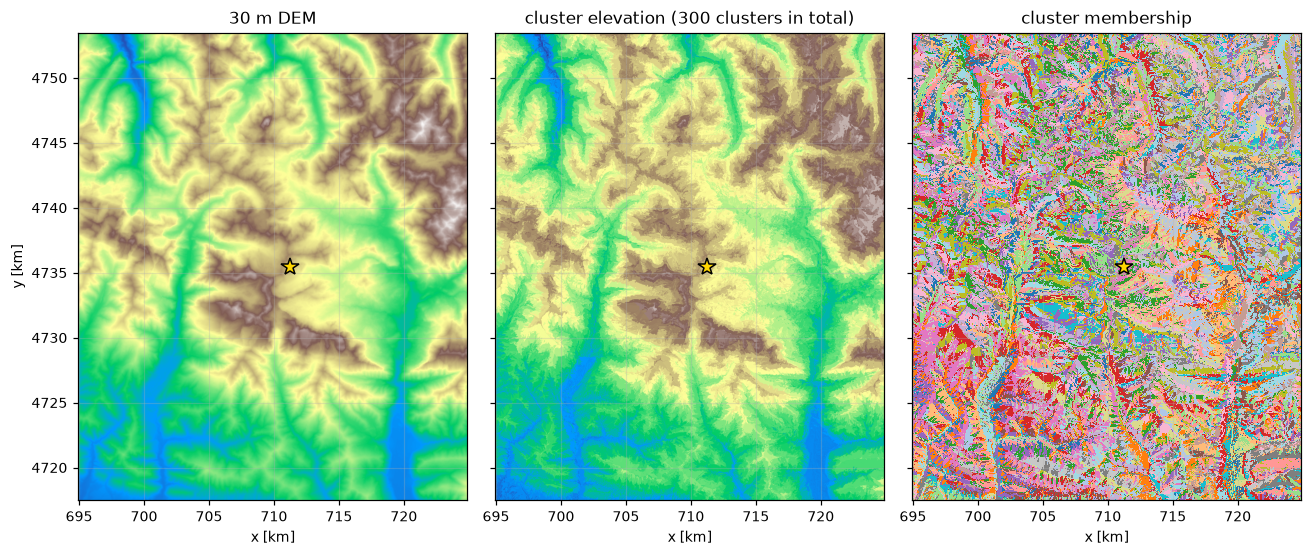

In [10]:
zoom = (tb[0], y_izas - 18e3, tb[2], y_izas + 18e3)          # 36 km around Izas, full transect width
zs = dem.sel(x=slice(zoom[0], zoom[2]), y=slice(zoom[3], zoom[1]))
ds_zoom = ds_param.sel(x=slice(zoom[0], zoom[2]), y=slice(zoom[3], zoom[1]))
ext = [km(zs.x[0]), km(zs.x[-1]), km(zs.y[-1]), km(zs.y[0])]
rng = np.random.default_rng(0)
shuffle = pd.Series(rng.permutation(len(cent)), index=cent.index)

fig, axs = plt.subplots(1, 3, figsize=(12, 7), sharey=True)
axs[0].imshow(zs, cmap="terrain", vmin=500, vmax=3100, extent=ext)
axs[0].set_title("30 m DEM")
axs[1].imshow(pu.to_grid(cent.elevation, ds_zoom), cmap="terrain", vmin=500, vmax=3100, extent=ext)
axs[1].set_title(f"cluster elevation ({len(cent)} clusters in total)")
axs[2].imshow(pu.to_grid(shuffle, ds_zoom), cmap="tab20", extent=ext, interpolation="nearest")
axs[2].set_title("cluster membership")
for a in axs:
    a.plot(km(x_izas), km(y_izas), "*", color="gold", mec="k", ms=12)
    a.set_xlabel("x [km]")
axs[0].set_ylabel("y [km]")
plt.tight_layout()
plt.show()

**Steps 3–5: solar geometry, horizons, downscaling.** Solar geometry is computed for every cluster and time step;
horizon angles (every 10°) are computed on the DEM and sampled at the cluster centroids; then each cluster is
downscaled from the 3×3 surrounding ERA5 cells.

In [11]:
with timed("transect: solar geometry"):
    mp.compute_solar_geometry()
with timed("transect: horizons"):
    mp.compute_horizon()
with timed("transect: downscaling"):
    if len(list((PROJ_T / "outputs" / "downscaled").glob("down_pt_*.nc"))) == len(cent):
        mp.load_project()
    else:
        mp.downscale_climate()
down = mp.downscaled_pts.load()
down

---> Solar file ds_solar.nc exists and loaded
[transect: solar geometry] 0.0 min
---> Horizon file da_horizon.nc exists and loaded


---> Centroids file df_centroids.pck updated with horizons
[transect: horizons] 0.1 min
---> Centroids file df_centroids.pck exists and loaded


---> DEM parameter file ds_param.nc exists and loaded
---> Solar file ds_solar.nc exists and loaded
---> Horizon file da_horizon.nc exists and loaded
---> Loading downscaled points 
 ...


---> Downscaled point files ds_param.nc exists and loaded
[transect: downscaling] 0.5 min


<xarray.Dataset> Size: 119MB
Dimensions:            (point_name: 300, time: 2924)
Coordinates:
  * point_name         (point_name) <U3 4kB '000' '001' '002' ... '298' '299'
    point_ind          (point_name) int64 2kB 0 1 2 3 4 ... 295 296 297 298 299
  * time               (time) datetime64[ns] 23kB 2019-01-01 ... 2020-12-31T1...
Data variables: (12/17)
    t                  (point_name, time) float64 7MB 286.6 285.0 ... 278.8
    u                  (point_name, time) float64 7MB 0.2664 -0.2005 ... 6.156
    v                  (point_name, time) float64 7MB -0.3426 -0.6233 ... 0.503
    q                  (point_name, time) float64 7MB 0.002217 ... 0.004567
    p                  (point_name, time) float64 7MB 8.996e+04 ... 9.813e+04
    precip_lapse_rate  (point_name, time) float64 7MB 1.057 1.057 ... 0.8475
    ...                 ...
    cse                (point_name, time) float64 7MB 0.6685 0.6631 ... 0.7377
    LW                 (point_name, time) float64 7MB 274.0 268.7 ... 316.6
    SW_diffuse         (point_name, time) float64 7MB 0.0 0.0 ... 144.3 0.0
    cos_illumination   (point_name, time) float64 7MB 0.03472 0.2482 ... 0.05327
    SW_direct          (point_name, time) float64 7MB 0.0 0.0 ... 135.1 0.0
    SW                 (point_name, time) float64 7MB 0.0 0.0 ... 279.5 0.0
Attributes:
    title:            Downscaled timeseries with TopoPyScale
    created with:     TopoPyScale, see more at https://topopyscale.readthedoc...
    package_version:  0.3.3
    git_commit:       89fe31ada38f1354d543588516af6263817675c2
    url_TopoPyScale:  https://github.com/ArcticSnow/TopoPyScale
    date_created:     2026-11-10 13:26:33

In [12]:
def du(p):
    p = Path(p)
    return sum(f.stat().st_size for f in p.rglob("*") if f.is_file()) if p.is_dir() else p.stat().st_size


out = PROJ_T / "outputs"
sizes = {f: du(out / f) / 1e6 for f in ("ds_param.nc", "da_horizon.nc", "ds_solar.nc", "df_centroids.pck", "downscaled")
         if (out / f).exists()}
print("Transect output sizes [MB]:", {k: round(v, 1) for k, v in sizes.items()})
pd.Series(TIMES).div(60).round(2).rename("minutes").to_frame()

Transect output sizes [MB]: {'ds_param.nc': 840.4, 'da_horizon.nc': 2541.7, 'ds_solar.nc': 2.3, 'df_centroids.pck': 0.1, 'downscaled': 116.9}


,minutes
download + ERA5 preparation,0.02
DEM preparation,0.01
transect: DEM parameters,1.06
transect: clustering,0.00
transect: solar geometry,0.00
transect: horizons,0.05
transect: downscaling,0.49


### 4b. Points mode at Izas

For the station comparison we use TopoPyScale's **points mode** on a 24 × 24 km window of the same 30 m DEM.
Besides the AWS itself we add two sets of virtual points around Izas:

* an **elevation series**: gentle-slope points from the valley floor to the summits (~200 m apart), and
* an **aspect rose**: 8 slopes at the station's elevation facing N, NE, …, NW.

> **Station position.** Izas AWS at 42.74268°N, 0.41912°W, 2113 m a.s.l. (station metadata, `pyr_utils.IZAS`).
> TopoPyScale uses the DEM elevation of the pixel (printed below), which is a few tens of metres lower; the
> observed pressure gives an independent check of the station elevation (section 6b). Note that the rounded value
> often quoted for the catchment (42°44′N, 0°25′W) is ~1 km away, on a steep south-east-facing slope: precise
> station coordinates matter at this scale.

In [13]:
DEM_IZAS = PROJ_I / "inputs" / "dem" / "dem_izas_30m.tif"
pu.cut_window(DEM_FILE, DEM_IZAS, pu.IZAS["lat"], pu.IZAS["lon"], half_km=12)
pu.install_climate(CLIM, PROJ_I)
print(pu.render_config(CODE_DIR / "config_izas_template.yml", PROJ_I / "config.yml", project_dir=PROJ_I,
                       cpu_cores=CPU_CORES, dem_file=DEM_IZAS.name)[-700:])
mp_i = tc.Topoclass(str(PROJ_I / "config.yml"))
with timed("Izas: DEM parameters"):
    mp_i.compute_dem_param()

pts = pu.izas_point_table(mp_i.toposub.ds_param)
pts[["name", "x", "y"]].to_csv(PROJ_I / "inputs" / "dem" / "izas_points.csv", index=False)
old = PROJ_I / "outputs" / "df_centroids.pck"                # points changed -> recompute the point outputs
if old.exists() and set(pd.read_pickle(old).point_name) != set(pts.name):
    for f in ("df_centroids.pck", "ds_solar.nc"):
        (PROJ_I / "outputs" / f).unlink(missing_ok=True)
    for f in (PROJ_I / "outputs" / "downscaled").glob("down_pt_*.nc"):
        f.unlink()

with timed("Izas: points, solar, horizons, downscaling"):
    mp_i.extract_topo_param()
    mp_i.compute_solar_geometry()
    mp_i.compute_horizon()
    if len(list((PROJ_I / "outputs" / "downscaled").glob("down_pt_*.nc"))) == len(pts):
        mp_i.load_project()
    else:
        mp_i.downscale_climate()
dsi = mp_i.downscaled_pts.load()

pt_info = mp_i.toposub.df_centroids.set_index("point_name")
pt_info["aspect_deg"] = pu.compass_aspect(pt_info.aspect)
pt_info["slope_deg"] = np.rad2deg(pt_info.slope)
pt_info = pt_info.join(pts.set_index("name")[["group", "target"]])
z_izas = float(pt_info.loc["Izas_AWS", "elevation"])
r = pt_info.loc["Izas_AWS"]
print(f"Izas AWS in the DEM: elevation {r.elevation:.0f} m (station {pu.IZAS['elev']:.0f} m), slope {r.slope_deg:.1f}°, "
      f"aspect {r.aspect_deg:.0f}°, SVF {r.svf:.2f}")
pt_info[["group", "elevation", "slope_deg", "aspect_deg", "svf"]].round(2)

p_lapse_rate: True

dem:
    file: dem_izas_30m.tif
    epsg: 32630
    horizon_increments: 10

sampling:
    method: points
    points:
        csv_file: izas_points.csv     # columns name, x, y (EPSG:32630), in inputs/dem/
        name_column: name

toposcale:
    interpolation_method: idw
    pt_sampling_method: nearest
    LW_terrain_contribution: True

outputs:
    directory:
    variables: all
    file:
        clean_outputs: False
        clean_FSM: False
        df_centroids: df_centroids.pck
        ds_param: ds_param.nc
        ds_solar: ds_solar.nc
        da_horizon: da_horizon.nc
        landform: landform.tif
        downscaled_pt: down_pt_*.nc

clean_up:
    rm_tmp_dirs: True


---> DEM file found
{'latN': 42.84731341279392, 'latS': 42.63800681788827, 'lonW': -0.5699885713706605, 'lonE': -0.2680965741898207}
Project lat/lon extent:

	------------------------------
	|        North:42.8          |
	|West:-0.6          East:-0.3|
	|        South:42.6          |
	-----------

---> File <DATA_ROOT>/izas/outputs/tmp/ds_param.nc saved
[Izas: DEM parameters] 0.0 min
---> Centroids file df_centroids.pck exists and loaded
---> Solar file ds_solar.nc exists and loaded


---> Horizon file da_horizon.nc exists and loaded


---> Centroids file df_centroids.pck updated with horizons
---> Centroids file df_centroids.pck exists and loaded
---> DEM parameter file ds_param.nc exists and loaded
---> Solar file ds_solar.nc exists and loaded
---> Horizon file da_horizon.nc exists and loaded
---> Loading downscaled points 
 ...


---> Downscaled point files ds_param.nc exists and loaded
[Izas: points, solar, horizons, downscaling] 0.0 min


Izas AWS in the DEM: elevation 2072 m (station 2113 m), slope 6.2°, aspect 44°, SVF 0.96


,group,elevation,slope_deg,aspect_deg,svf
point_name,,,,,
Izas_AWS,station,2072.41,6.22,43.73,0.96
elev_1400,elevation_series,1438.92,4.87,97.47,0.90
elev_1600,elevation_series,1628.50,0.76,131.73,0.96
elev_1800,elevation_series,1820.96,1.40,5.33,0.95
elev_2000,elevation_series,2020.63,0.66,326.75,0.97
elev_2200,elevation_series,2192.05,0.51,243.81,0.99
elev_2400,elevation_series,2385.08,3.00,7.17,1.00
elev_2600,elevation_series,2564.87,3.83,159.62,0.95
elev_2800,elevation_series,2782.44,22.44,19.77,0.95


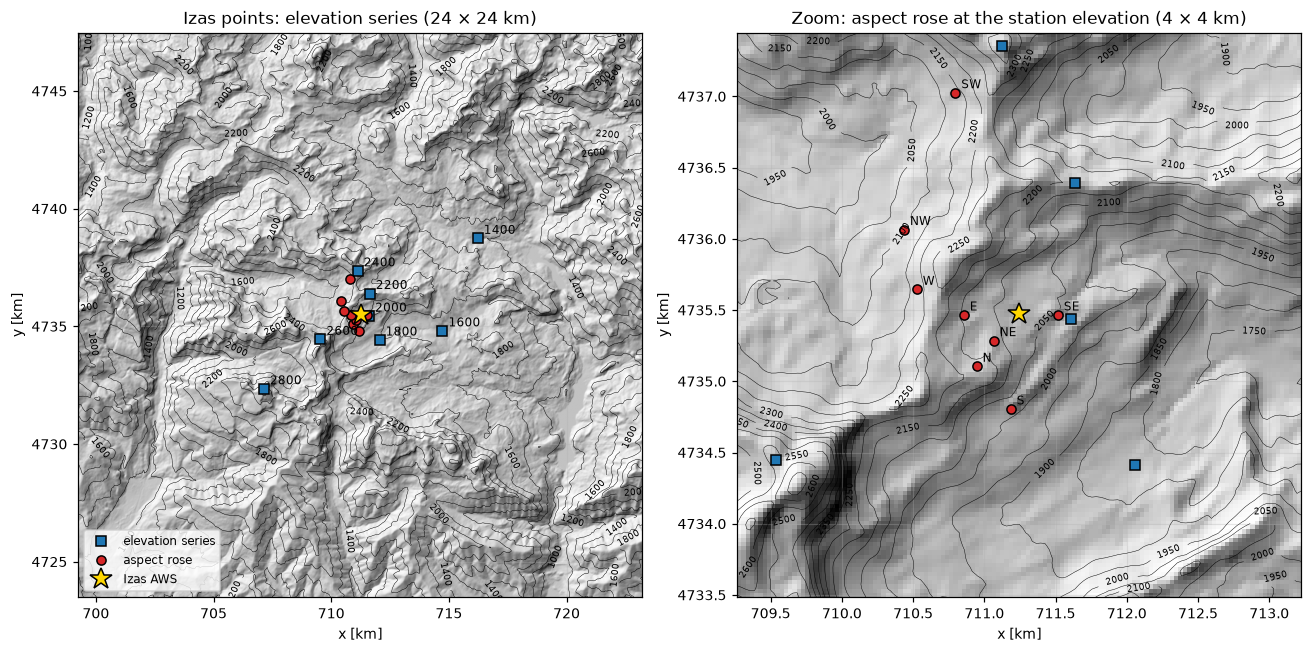

In [14]:
win = xr.open_dataarray(DEM_IZAS, engine="rasterio").squeeze("band", drop=True)
fig, axs = plt.subplots(1, 2, figsize=(12, 6))
for ax, half, step in ((axs[0], 12e3, 200), (axs[1], 2e3, 50)):
    w = win.sel(x=slice(x_izas - half, x_izas + half), y=slice(y_izas + half, y_izas - half))
    e = [km(w.x[0]), km(w.x[-1]), km(w.y[-1]), km(w.y[0])]
    ax.imshow(pu.hillshade(w.values, DEM_RES), cmap="gray", extent=e)
    cs = ax.contour(km(w.x), km(w.y), w.values, levels=np.arange(1000, 3200, step), colors="k", linewidths=0.3)
    ax.clabel(cs, fontsize=6)
    for g, mk, c in (("elevation_series", "s", "tab:blue"), ("aspect_rose", "o", "tab:red")):
        p = pt_info[(pt_info.group == g) & (abs(pt_info.x - x_izas) < half) & (abs(pt_info.y - y_izas) < half)]
        ax.plot(km(p.x), km(p.y), mk, color=c, mec="k", label=g.replace("_", " "))
        if (g == "aspect_rose") == (half < 5e3):   # label the rose in the zoom, the elevation series in the overview
            for n, r in p.iterrows():
                ax.annotate(n.split("_")[-1], (km(r.x), km(r.y)), xytext=(4, 3), textcoords="offset points", fontsize=8)
    ax.plot(km(x_izas), km(y_izas), "*", color="gold", mec="k", ms=15, label="Izas AWS")
    ax.set(xlabel="x [km]", ylabel="y [km]")
axs[0].legend(loc="lower left", fontsize=8)
axs[0].set_title("Izas points: elevation series (24 × 24 km)")
axs[1].set_title("Zoom: aspect rose at the station elevation (4 × 4 km)")
plt.tight_layout()
plt.show()

### Station data and the raw-ERA5 reference

* **Observations** are matched to the model time stamps: SW is averaged over the hour *ending* at each time stamp
  (exactly what the ERA5 accumulation represents); T, RH, pressure and wind are averaged over ±10 min.
* **Raw ERA5** is taken from the **nearest grid cell** to Izas (no interpolation), at its model elevation.
* TopoPyScale's SW is on the inclined surface of the DEM pixel (here 6°, NE-facing), while the pyranometer is
  levelled: for the comparison we use the **horizontal-equivalent** SW (`SW_horiz`, same diffuse, sky view and
  shading, direct beam on a horizontal plane).

In [15]:
obs10 = pu.load_izas(paths["izas_xlsx"], cache=DATA_ROOT / "raw" / "izas_10min.pkl")
mtimes = dsi.time.to_index()
obs = pu.izas_at(obs10, mtimes)
era = pu.era5_nearest(CLIM, pu.IZAS["lat"], pu.IZAS["lon"])
tps = pu.downscaled_df(dsi.sel(point_name="Izas_AWS"), mp_i.ds_solar.sel(point_name="Izas_AWS"))
pid_izas = str(ds_param.point_name.sel(x=x_izas, y=y_izas, method="nearest").item())
tps_cl = pu.downscaled_df(down.sel(point_name=pid_izas), mp.ds_solar.sel(point_name=pid_izas))
print(f"Nearest ERA5 cell: {era.attrs['lat']:.2f}N {era.attrs['lon']:.3f}E, orography {era.attrs['oro']:.0f} m "
      f"({z_izas - era.attrs['oro']:.0f} m below the station)")
print(f"Transect cluster containing Izas: {pid_izas} (centroid elevation {cent.loc[pid_izas, 'elevation']:.0f} m)")

Nearest ERA5 cell: 42.62N -0.311E, orography 1372 m (700 m below the station)
Transect cluster containing Izas: 141 (centroid elevation 2018 m)


## 5. The long-distance North–South gradient

All analyses below use the **per-cluster time series**. Maps are made by painting each cluster's value onto its
pixels on the fly; latitudinal profiles use the number of pixels of each cluster in each latitude band, so no
gridded output is ever stored.

The maps and profiles of this section are **time averages over the two years 2019–2020, not single time steps**:

* **temperature**: mean of all 6-hourly values (4 per day);
* **precipitation**: mean annual total, from the 1-hour rates × 6 h (a sampled estimate);
* **shortwave**: mean of the daily **12 UTC** values (hour 11–12 UTC, ≈ solar noon).

In [16]:
tt = down.time.to_index()
DJF, JJA = tt.month.isin([12, 1, 2]), tt.month.isin([6, 7, 8])
H12 = tt.hour == 12
nyears = 2.0


def tmean(da, sel=None):
    return (da if sel is None else da.isel(time=np.where(sel)[0])).mean("time").to_series()


clus = pd.DataFrame({
    "T": tmean(down.t) - 273.15, "T_DJF": tmean(down.t, DJF) - 273.15, "T_JJA": tmean(down.t, JJA) - 273.15,
    "P": down.tp.sum("time").to_series() / nyears,
    "P_nolapse": (down.tp / down.precip_lapse_rate).sum("time").to_series() / nyears,
    "SW12": tmean(down.SW, H12), "SW12_DJF": tmean(down.SW, H12 & DJF), "SW12_JJA": tmean(down.SW, H12 & JJA),
}).join(cent[["elevation", "slope_deg", "aspect_deg", "northness", "svf", "lat", "lon"]])

# ERA5 along the two transect columns, same statistics
ct = cols.time.to_index()
era_cols = xr.Dataset({
    "T": cols.t2m.mean("time") - 273.15, "T_DJF": cols.t2m.isel(time=np.where(ct.month.isin([12, 1, 2]))[0]).mean("time") - 273.15,
    "T_JJA": cols.t2m.isel(time=np.where(ct.month.isin([6, 7, 8]))[0]).mean("time") - 273.15,
    "P": (cols.tp * 1000 * 6).sum("time") / nyears,
    "SW12": (cols.ssrd / 3600).isel(time=np.where(ct.hour == 12)[0]).mean("time"), "oro": cols.oro})
era_df = era_cols.to_dataframe().reset_index()

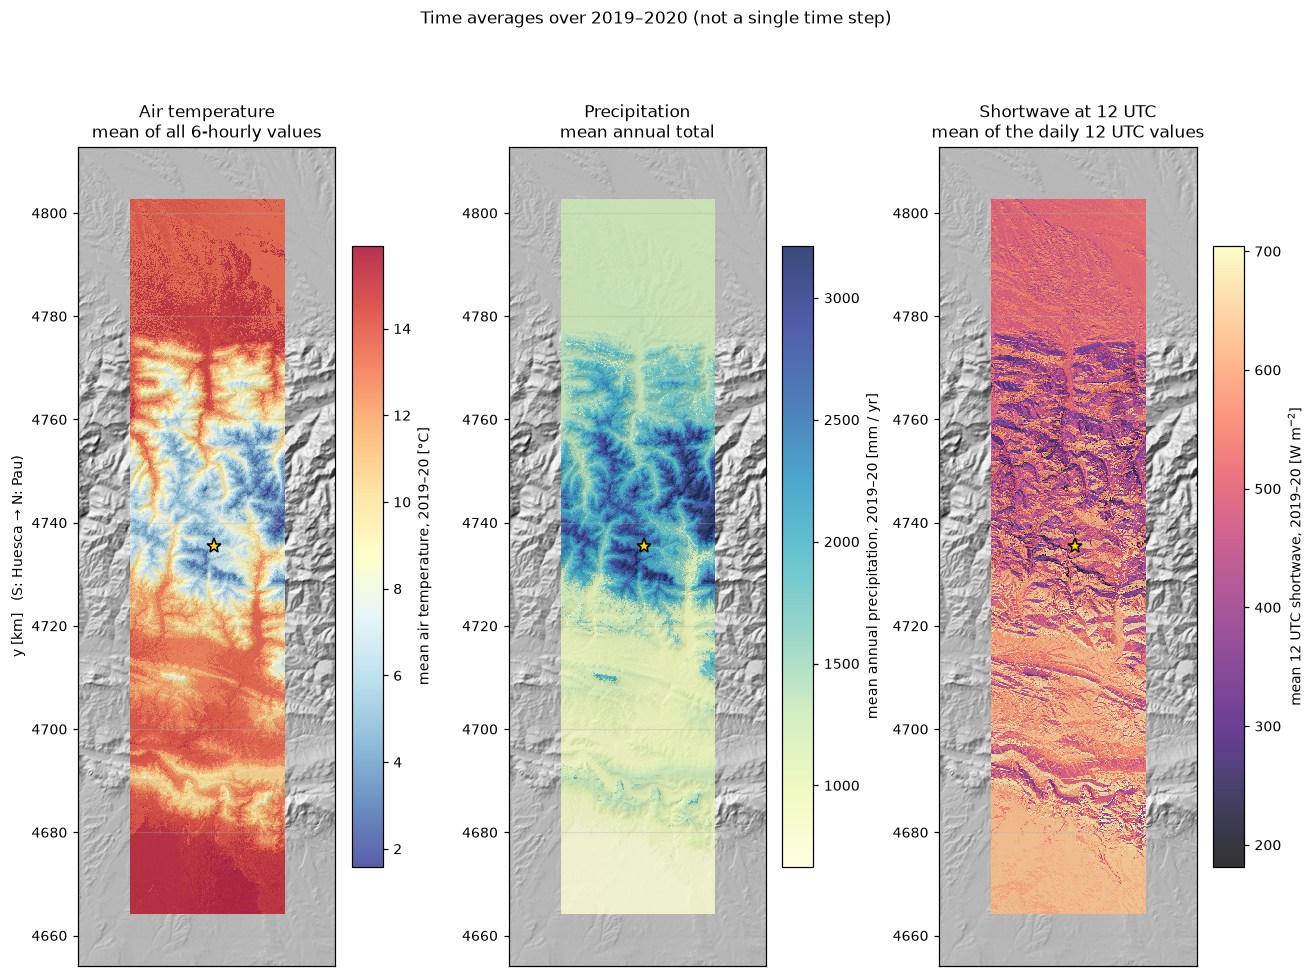

In [17]:
def show(ax, values, cmap, label, vmin=None, vmax=None, stride=6, params=ds_param, extent=None):
    g = pu.to_grid(values, params, stride=stride)
    e = extent or [km(g.x[0]), km(g.x[-1]), km(g.y[-1]), km(g.y[0])]
    d = dem.sel(x=g.x, y=g.y, method="nearest")
    ax.imshow(pu.hillshade(d.values, DEM_RES * stride), cmap="gray", extent=e)
    im = ax.imshow(g, cmap=cmap, vmin=vmin, vmax=vmax, alpha=0.8, extent=e, interpolation="nearest")
    plt.colorbar(im, ax=ax, shrink=0.6, label=label)
    ax.plot(km(x_izas), km(y_izas), "*", color="gold", mec="k", ms=10)
    ax.set_xticks([])
    return im


fig, axs = plt.subplots(1, 3, figsize=(12, 10))
show(axs[0], clus["T"], "RdYlBu_r", "mean air temperature, 2019–20 [°C]")
show(axs[1], clus["P"], "YlGnBu", "mean annual precipitation, 2019–20 [mm / yr]", vmax=np.nanpercentile(clus.P, 98))
show(axs[2], clus["SW12"], "magma", "mean 12 UTC shortwave, 2019–20 [W m$^{-2}$]")
for a, t in zip(axs, ["Air temperature\nmean of all 6-hourly values", "Precipitation\nmean annual total",
                      "Shortwave at 12 UTC\nmean of the daily 12 UTC values"]):
    a.set_title(t)
axs[0].set_ylabel("y [km]   (S: Huesca → N: Pau)")
fig.suptitle("Time averages over 2019–2020 (not a single time step)", fontsize=11)
plt.tight_layout()
plt.show()

To separate the **climatic** N–S gradient from the **topographic** one, we compare latitudinal profiles at the
*same elevation band* (1500–2000 m) and for *flat* terrain only. The profiles show the same **2019–2020
averages** as the maps; ERA5 cell values (same averages) are shown as squares and diamonds.

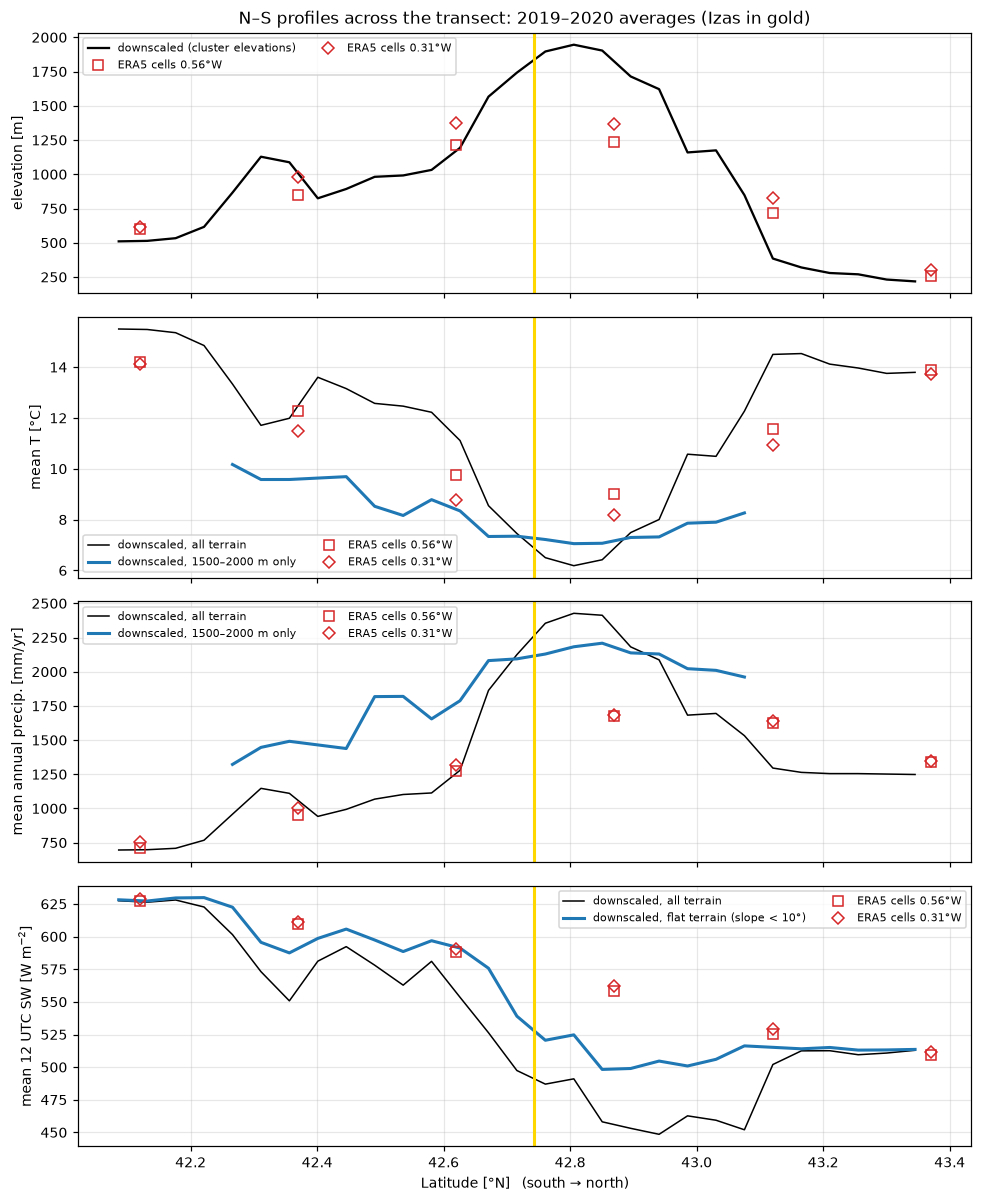

In [18]:
elev_px = ds_param.elevation.values
slope_px = np.rad2deg(ds_param.slope.values)
W_all = pu.lat_weights(ds_param, bin_km=5)
W_band = pu.lat_weights(ds_param, bin_km=5, by=(elev_px > 1500) & (elev_px < 2000))
W_flat = pu.lat_weights(ds_param, bin_km=5, by=slope_px < 10)

fig, axs = plt.subplots(4, 1, figsize=(9, 11), sharex=True)
axs[0].plot(W_all.index, pu.profile(W_all, clus.elevation), "k", label="downscaled (cluster elevations)")
axs[0].set_ylabel("elevation [m]")
for var, ax, lab in (("T", axs[1], "mean T [°C]"), ("P", axs[2], "mean annual precip. [mm/yr]"),
                     ("SW12", axs[3], "mean 12 UTC SW [W m$^{-2}$]")):
    ax.plot(W_all.index, pu.profile(W_all, clus[var]), "k", lw=1, label="downscaled, all terrain")
    if var != "SW12":
        b = pu.profile(W_band, clus[var])
        ax.plot(b.index, b, "tab:blue", lw=2, label="downscaled, 1500–2000 m only")
    else:
        f = pu.profile(W_flat, clus[var])
        ax.plot(f.index, f, "tab:blue", lw=2, label="downscaled, flat terrain (slope < 10°)")
    ax.set_ylabel(lab)
for ax, var in zip(axs, ["oro", "T", "P", "SW12"]):
    for lo, mk in zip(cols.longitude.values, ["s", "D"]):
        e_ = era_df[era_df.longitude == lo]
        ax.plot(e_.latitude, e_[var], mk, color="tab:red", mfc="none", label=f"ERA5 cells {abs(lo):.2f}°W")
    ax.axvline(pu.IZAS["lat"], color="gold", lw=2)
    ax.legend(fontsize=7, ncol=2)
axs[-1].set_xlabel("Latitude [°N]   (south → north)")
axs[0].set_title("N–S profiles across the transect: 2019–2020 averages (Izas in gold)")
plt.tight_layout()
plt.show()

**Reading the profiles.** At the *same elevation* the downscaled temperature still carries the large-scale
gradient of ERA5, while the all-terrain curve follows the topography. Precipitation is highest on the Atlantic
(northern) side. Flat-terrain shortwave shows the cloudiness contrast: more sun on the southern side.

## 6. The elevation gradient

### 6a. Along the transect

Each dot is a cluster. ERA5 cells (red squares) only span a few hundred metres of elevation and therefore
cannot represent the temperature contrast between valley floors and summits.

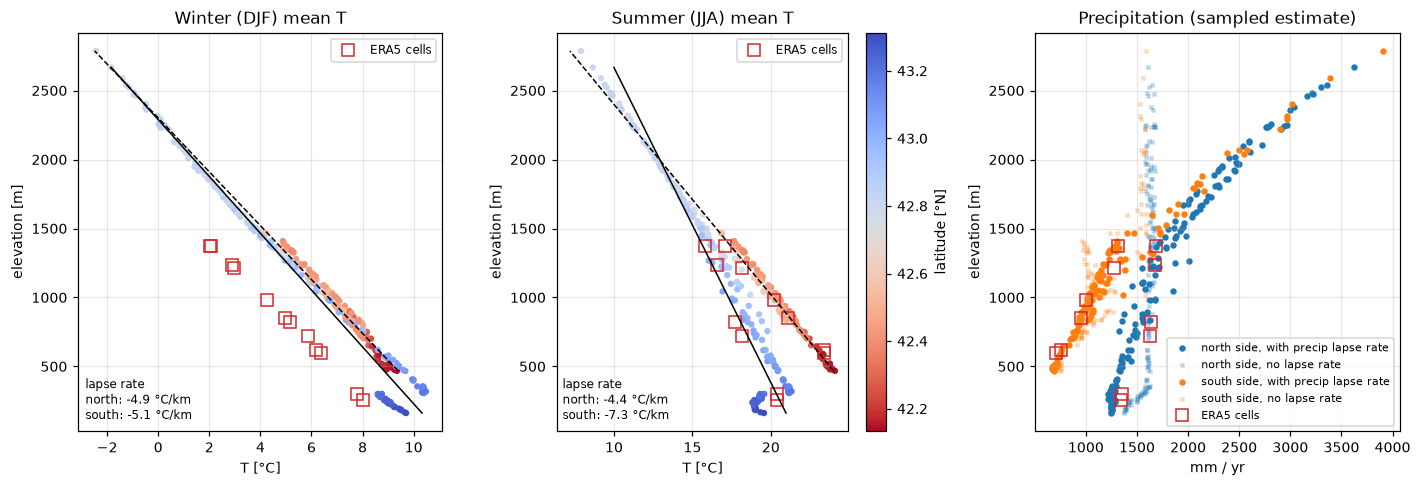

In [19]:
DIVIDE_LAT = 42.80                                   # approximate main divide along the transect
clus["side"] = np.where(clus.lat > DIVIDE_LAT, "north", "south")
fig, axs = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, var, title in ((axs[0], "T_DJF", "Winter (DJF) mean T"), (axs[1], "T_JJA", "Summer (JJA) mean T")):
    sc = ax.scatter(clus[var], clus.elevation, c=clus.lat, cmap="coolwarm_r", s=10)
    ax.plot(era_df[var], era_df.oro, "s", color="tab:red", mfc="none", ms=8, label="ERA5 cells")
    txt = []
    for side, ls in (("north", "-"), ("south", "--")):
        c = clus[clus.side == side]
        a, b = np.polyfit(c.elevation / 1000, c[var], 1)
        zz = np.linspace(c.elevation.min(), c.elevation.max(), 10)
        ax.plot(a * zz / 1000 + b, zz, "k", ls=ls, lw=1)
        txt.append(f"{side}: {a:.1f} °C/km")
    ax.set(title=title, xlabel="T [°C]", ylabel="elevation [m]")
    ax.text(0.02, 0.02, "lapse rate\n" + "\n".join(txt), transform=ax.transAxes, fontsize=8, va="bottom")
    ax.legend(loc="upper right", fontsize=8)
plt.colorbar(sc, ax=axs[1], label="latitude [°N]")
for side, c in (("north", "tab:blue"), ("south", "tab:orange")):
    s_ = clus[clus.side == side]
    axs[2].scatter(s_.P, s_.elevation, s=10, color=c, label=f"{side} side, with precip lapse rate")
    axs[2].scatter(s_.P_nolapse, s_.elevation, s=6, color=c, alpha=0.3, marker="x", label=f"{side} side, no lapse rate")
axs[2].plot(era_df.P, era_df.oro, "s", color="tab:red", mfc="none", ms=8, label="ERA5 cells")
axs[2].set(title="Precipitation (sampled estimate)", xlabel="mm / yr", ylabel="elevation [m]")
axs[2].legend(fontsize=7)
plt.tight_layout()
plt.show()

### 6b. At Izas: does the downscaled profile hit the station?

The elevation series around Izas spans ~1200–2800 m within a few km, i.e. **inside one ERA5 cell**. The station
(gold star) measures one point of that profile; raw ERA5 (red square) sits at the model's 1372 m surface.
Means are computed over the time steps where observations are available.

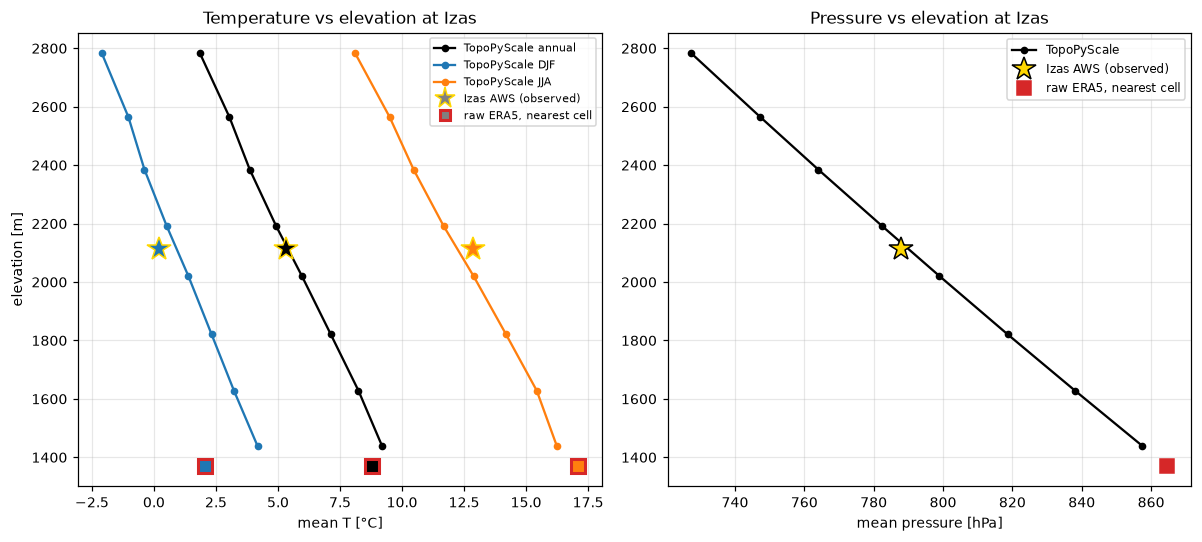

raw ERA5    : T bias +3.45 °C,  P bias +76.8 hPa
TopoPyScale : T bias +0.36 °C,  P bias +6.1 hPa
Station elevation implied by the observed pressure on the downscaled profile: 2135 m (station 2113 m, DEM pixel 2072 m)


In [20]:
ok = obs["T"].notna() & obs["P"].notna()
Z_STN = pu.IZAS["elev"]                         # observations plotted at the station elevation
es = pt_info[pt_info.group == "elevation_series"].sort_values("elevation")
seas = {"annual": np.ones(len(mtimes), bool), "DJF": mtimes.month.isin([12, 1, 2]), "JJA": mtimes.month.isin([6, 7, 8])}
fig, axs = plt.subplots(1, 2, figsize=(11, 5))
for (sname, sm), c in zip(seas.items(), ["k", "tab:blue", "tab:orange"]):
    m = sm & ok.to_numpy()
    tz = [float(dsi.t.sel(point_name=n).isel(time=np.where(m)[0]).mean()) - 273.15 for n in es.index]
    axs[0].plot(tz, es.elevation, "-o", color=c, ms=4, label=f"TopoPyScale {sname}")
    axs[0].plot(obs["T"][m].mean(), Z_STN, "*", color=c, mec="gold", ms=16)
    axs[0].plot(era["T"][m].mean(), era.attrs["oro"], "s", color=c, mec="tab:red", mew=2, ms=9)
axs[0].plot([], [], "*", color="0.5", mec="gold", ms=14, label="Izas AWS (observed)")
axs[0].plot([], [], "s", color="0.5", mec="tab:red", mew=2, label="raw ERA5, nearest cell")
axs[0].set(xlabel="mean T [°C]", ylabel="elevation [m]", title="Temperature vs elevation at Izas")
axs[0].legend(fontsize=7)
pz = [float(dsi.p.sel(point_name=n).isel(time=np.where(ok)[0]).mean()) / 100 for n in es.index]
axs[1].plot(pz, es.elevation, "-o", color="k", ms=4, label="TopoPyScale")
axs[1].plot(obs["P"][ok].mean(), Z_STN, "*", color="gold", mec="k", ms=16, label="Izas AWS (observed)")
axs[1].plot(era["P"][ok].mean(), era.attrs["oro"], "s", color="tab:red", ms=9, label="raw ERA5, nearest cell")
axs[1].set(xlabel="mean pressure [hPa]", title="Pressure vs elevation at Izas")
axs[1].legend(fontsize=8)
plt.tight_layout()
plt.show()
for name, d in (("raw ERA5", era), ("TopoPyScale", tps)):
    print(f"{name:12s}: T bias {d['T'][ok].mean() - obs['T'][ok].mean():+.2f} °C,  "
          f"P bias {d['P'][ok].mean() - obs['P'][ok].mean():+.1f} hPa")
z_from_p = np.interp(obs["P"][ok].mean(), np.array(pz)[::-1], es.elevation.values[::-1])
print(f"Station elevation implied by the observed pressure on the downscaled profile: {z_from_p:.0f} m "
      f"(station {pu.IZAS['elev']:.0f} m, DEM pixel {z_izas:.0f} m)")

## 7. Terrain and shortwave radiation

### 7a. Along the transect

A clear winter day at noon: ERA5 has one value per ~31 km cell, TopoPyScale resolves sunny south faces, shaded
north faces and cast shadows.

Clearest Dec/Jan noon: 2019-01-24 12:00:00


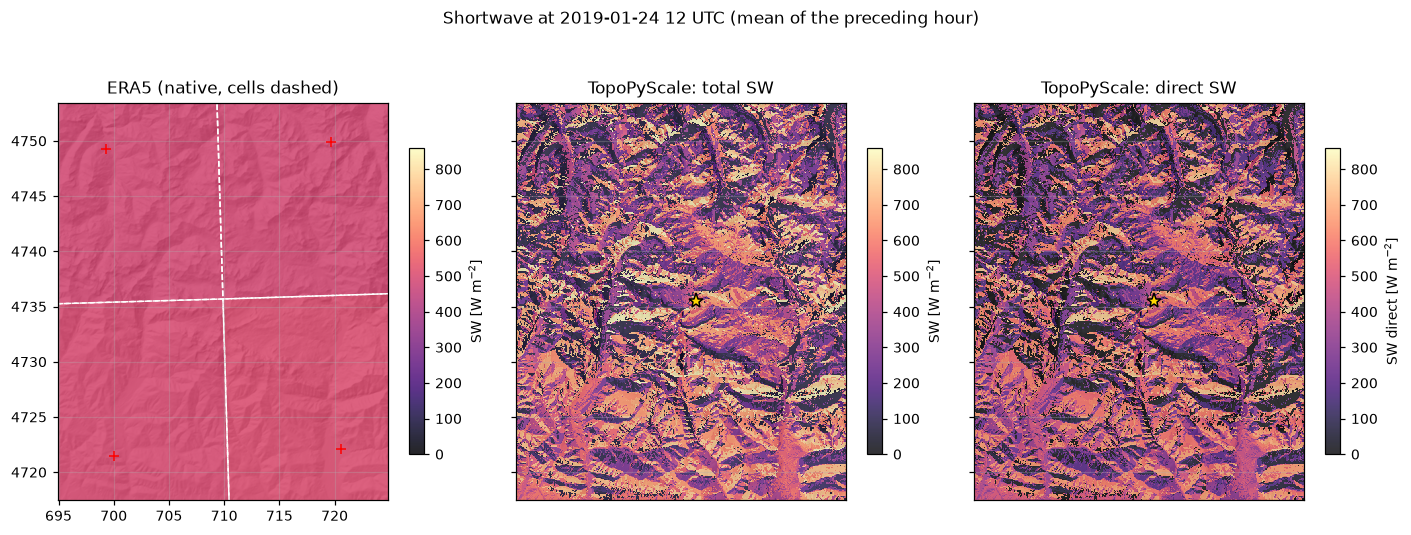

In [21]:
dj12 = np.where((ct.hour == 12) & ct.month.isin([12, 1]))[0]
t_clear = ct[dj12][int((cols.ssrd.isel(time=dj12)).mean(["latitude", "longitude"]).argmax())]
print("Clearest Dec/Jan noon:", t_clear)
zoom_params = ds_param.sel(x=slice(zoom[0], zoom[2]), y=slice(zoom[3], zoom[1]))
st = 2
gx, gy = zoom_params.x.values[::st], zoom_params.y.values[::st]
era_sw = pu.era5_display_map((pu.open_era5_surf(CLIM).ssrd.sel(time=t_clear) / 3600).load(), gx, gy)
snap = down.sel(time=t_clear)
fig, axs = plt.subplots(1, 3, figsize=(13, 5.2), sharey=True)
e = [km(gx[0]), km(gx[-1]), km(gy[-1]), km(gy[0])]
vmax = float(snap.SW.max())
axs[0].imshow(pu.hillshade(dem.sel(x=gx, y=gy, method="nearest").values, DEM_RES * st), cmap="gray", extent=e)
im = axs[0].imshow(era_sw, cmap="magma", vmin=0, vmax=vmax, alpha=0.85, extent=e)
draw_era5_cells(axs[0], era5_cells_in((zoom[0] - 15e3, zoom[1] - 15e3, zoom[2] + 15e3, zoom[3] + 15e3)), ec="w", lw=1, ls="--")
axs[0].set(xlim=e[:2], ylim=e[2:], title="ERA5 (native, cells dashed)")
show(axs[1], snap.SW.to_series(), "magma", "SW [W m$^{-2}$]", 0, vmax, stride=st, params=zoom_params)
axs[1].set_title("TopoPyScale: total SW")
show(axs[2], snap.SW_direct.to_series(), "magma", "SW direct [W m$^{-2}$]", 0, vmax, stride=st, params=zoom_params)
axs[2].set_title("TopoPyScale: direct SW")
plt.colorbar(im, ax=axs[0], shrink=0.6, label="SW [W m$^{-2}$]")
fig.suptitle(f"Shortwave at {t_clear:%Y-%m-%d %H} UTC (mean of the preceding hour)")
plt.tight_layout()
plt.show()

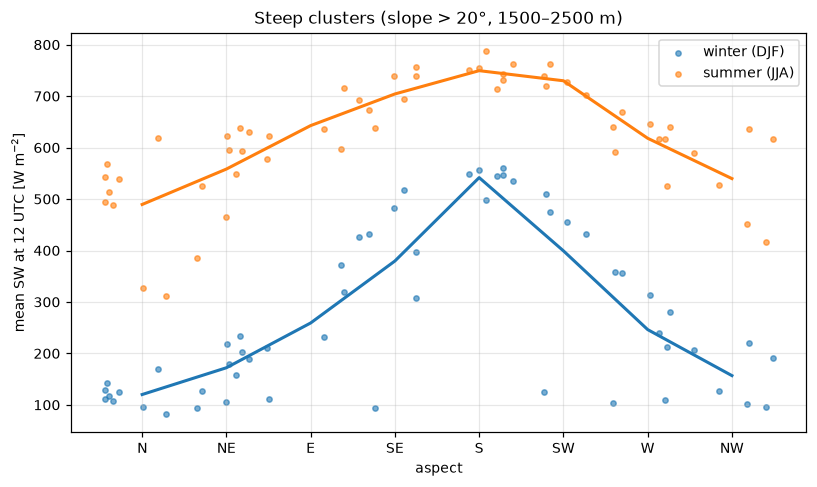

Winter noon SW, steep south-facing vs north-facing clusters: 471 vs 126 W m-2


In [22]:
steep = clus[(clus.slope_deg > 20) & clus.elevation.between(1500, 2500)]
bins = np.arange(-22.5, 360, 45)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
axs = [ax]
for var, c, lab in (("SW12_DJF", "tab:blue", "winter (DJF)"), ("SW12_JJA", "tab:orange", "summer (JJA)")):
    a = np.mod(steep.aspect_deg + 22.5, 360) - 22.5
    axs[0].scatter(a, steep[var], s=12, color=c, alpha=0.6, label=lab)
    binned = steep[var].groupby(pd.cut(a, bins)).mean()
    axs[0].plot(bins[:-1] + 22.5, binned.values, "-", color=c, lw=2)
axs[0].set(xticks=range(0, 360, 45), xticklabels=list(pu.DIRECTIONS), xlabel="aspect",
           ylabel="mean SW at 12 UTC [W m$^{-2}$]", title="Steep clusters (slope > 20°, 1500–2500 m)")
axs[0].legend()
plt.tight_layout()
plt.show()

south = steep[(steep.aspect_deg > 135) & (steep.aspect_deg < 225)].SW12_DJF.mean()
north = steep[(steep.aspect_deg < 45) | (steep.aspect_deg > 315)].SW12_DJF.mean()
print(f"Winter noon SW, steep south-facing vs north-facing clusters: {south:.0f} vs {north:.0f} W m-2")
assert south > north + 50, "south-facing slopes should receive much more winter noon SW"

### 7b. At Izas: the aspect rose next to the station

The Izas pyranometer is **horizontal**, so it measures what TopoPyScale computes for the station point (including
horizon shading). The 8 rose slopes at the same elevation show how much the aspect changes the radiation,
relative to that measured reference.

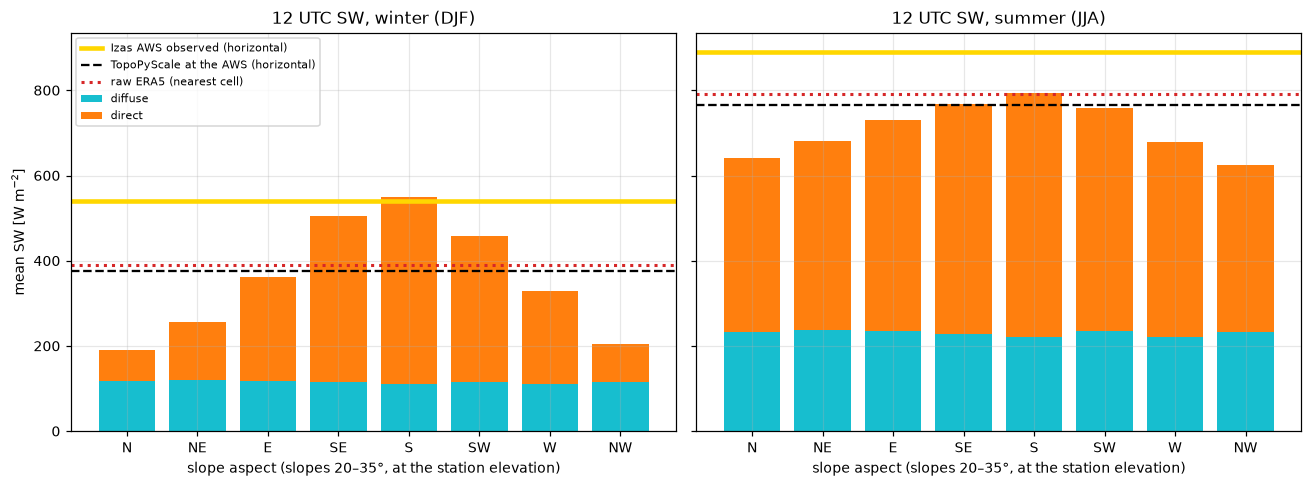

In [23]:
rose = pt_info[pt_info.group == "aspect_rose"].sort_values("target")
m12 = mtimes.hour == 12
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (sname, sm) in zip(axs, (("winter (DJF)", mtimes.month.isin([12, 1, 2])), ("summer (JJA)", mtimes.month.isin([6, 7, 8])))):
    m = m12 & sm & obs["SW"].notna().to_numpy()
    idx = np.where(m)[0]
    dir_ = [float(dsi.SW_direct.sel(point_name=n).isel(time=idx).mean()) for n in rose.index]
    dif_ = [float(dsi.SW_diffuse.sel(point_name=n).isel(time=idx).mean()) for n in rose.index]
    xs = np.arange(len(rose))
    ax.bar(xs, dif_, color="tab:cyan", label="diffuse")
    ax.bar(xs, dir_, bottom=dif_, color="tab:orange", label="direct")
    ax.axhline(obs["SW"][m].mean(), color="gold", lw=3, label="Izas AWS observed (horizontal)")
    ax.axhline(tps["SW_horiz"][m].mean(), color="k", ls="--", label="TopoPyScale at the AWS (horizontal)")
    ax.axhline(era["SW"][m].mean(), color="tab:red", ls=":", lw=2, label="raw ERA5 (nearest cell)")
    ax.set(xticks=xs, xticklabels=[n.split("_")[-1] for n in rose.index], title=f"12 UTC SW, {sname}",
           xlabel="slope aspect (slopes 20–35°, at the station elevation)")
axs[0].set_ylabel("mean SW [W m$^{-2}$]")
axs[0].legend(fontsize=7, loc="upper left")
plt.tight_layout()
plt.show()

## 8. Validation at the Izas AWS

### Horizon and sun path

TopoPyScale's horizon angles at the station (from the 30 m DEM) with the sun path on the solstices. When the sun is
below the local horizon only diffuse radiation reaches the station. Our 6-hourly samples are marked.

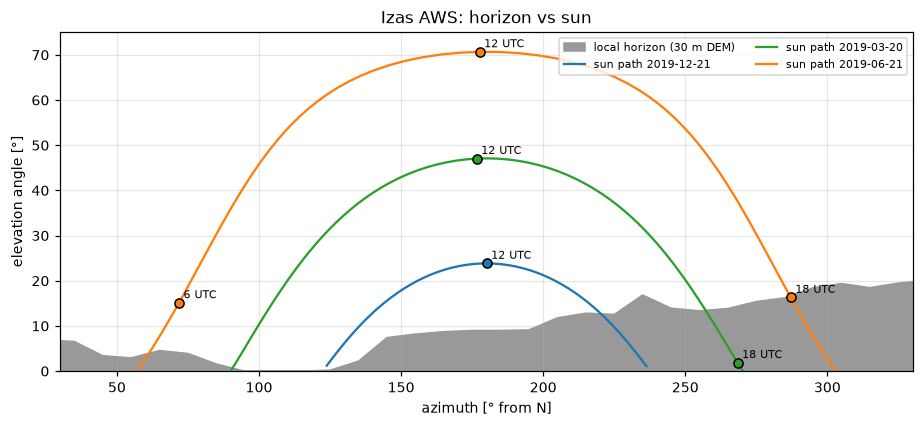

In [24]:
import pvlib

hz = mp_i.da_horizon.sel(x=x_izas, y=y_izas, method="nearest")
hz_az = np.mod(180 - hz.azimuth.values, 360)          # TopoPyScale/topocalc azimuth: 0 = South, +East
order = np.argsort(hz_az)
fig, ax = plt.subplots(figsize=(10, 4))
ax.fill_between(np.r_[hz_az[order], hz_az[order][0] + 360], 0, np.rad2deg(np.r_[hz.values[order], hz.values[order][0]]),
                color="0.6", label="local horizon (30 m DEM)")
for day, c in (("2019-12-21", "tab:blue"), ("2019-03-20", "tab:green"), ("2019-06-21", "tab:orange")):
    tday = pd.date_range(day, periods=24 * 6, freq="10min", tz="UTC")
    sp = pvlib.solarposition.get_solarposition(tday, pu.IZAS["lat"], pu.IZAS["lon"], altitude=z_izas)
    up = sp.apparent_elevation > 0
    ax.plot(sp.azimuth[up], sp.apparent_elevation[up], color=c, label=f"sun path {day}")
    for h in (6, 12, 18):
        s = sp[sp.index.hour == h].iloc[:1]
        if float(s.apparent_elevation.iloc[0]) > 0:
            ax.plot(s.azimuth, s.apparent_elevation, "o", color=c, mec="k")
            ax.annotate(f"{h} UTC", (float(s.azimuth.iloc[0]), float(s.apparent_elevation.iloc[0])), fontsize=7,
                        xytext=(3, 3), textcoords="offset points")
ax.set(xlim=(30, 330), ylim=(0, 75), xlabel="azimuth [° from N]", ylabel="elevation angle [°]",
       title="Izas AWS: horizon vs sun")
ax.legend(fontsize=7, ncol=2)
plt.show()

### Station vs raw ERA5 vs TopoPyScale

Three model estimates at the station: **raw ERA5** (nearest cell, at 1372 m), **TopoPyScale points mode** at the
AWS, and the **transect cluster** that contains the AWS (TopoSUB). Shortwave is compared at the **12 UTC**
samples (hour 11–12 UTC, around solar noon), with the TopoPyScale horizontal-equivalent SW.

In [25]:
hours = mtimes.hour
day = np.asarray(hours == 12)                    # SW validation at the 12 UTC samples
rows = {}
for var, lab in (("T", "T [°C]"), ("RH", "RH [%]"), ("P", "pressure [hPa]"), ("WS", "wind speed [m/s]")):
    for name, d in (("raw ERA5", era), ("TopoPyScale point", tps), ("TopoPyScale cluster", tps_cl)):
        if var in d:
            rows[(lab, name)] = pu.metrics(obs[var], d[var])
for name, d, v in (("raw ERA5", era, "SW"), ("TopoPyScale point", tps, "SW_horiz"),
                   ("TopoPyScale cluster", tps_cl, "SW_horiz")):
    rows[("SW 12 UTC [W m-2]", name)] = pu.metrics(obs["SW"][day], d[v][day])
met = pd.DataFrame(rows).T
met.round(2)

bias    RMSE     r       n
T [°C]            raw ERA5               3.45    4.85  0.90  2923.0
                  TopoPyScale point      0.36    1.85  0.96  2923.0
                  TopoPyScale cluster    0.46    1.96  0.96  2923.0
RH [%]            raw ERA5               7.05   22.05  0.53  2923.0
                  TopoPyScale point     -2.87   12.75  0.86  2923.0
                  TopoPyScale cluster   -1.21   13.07  0.85  2923.0
pressure [hPa]    raw ERA5              76.82   76.84  0.98  2923.0
                  TopoPyScale point      6.06    6.09  1.00  2923.0
                  TopoPyScale cluster   11.35   11.37  1.00  2923.0
wind speed [m/s]  TopoPyScale point      2.72    4.29  0.53  2923.0
                  TopoPyScale cluster    2.45    3.92  0.54  2923.0
SW 12 UTC [W m-2] raw ERA5            -124.92  281.55  0.74   731.0
                  TopoPyScale point   -144.03  291.29  0.73   731.0
                  TopoPyScale cluster -165.49  305.49  0.72   731.0

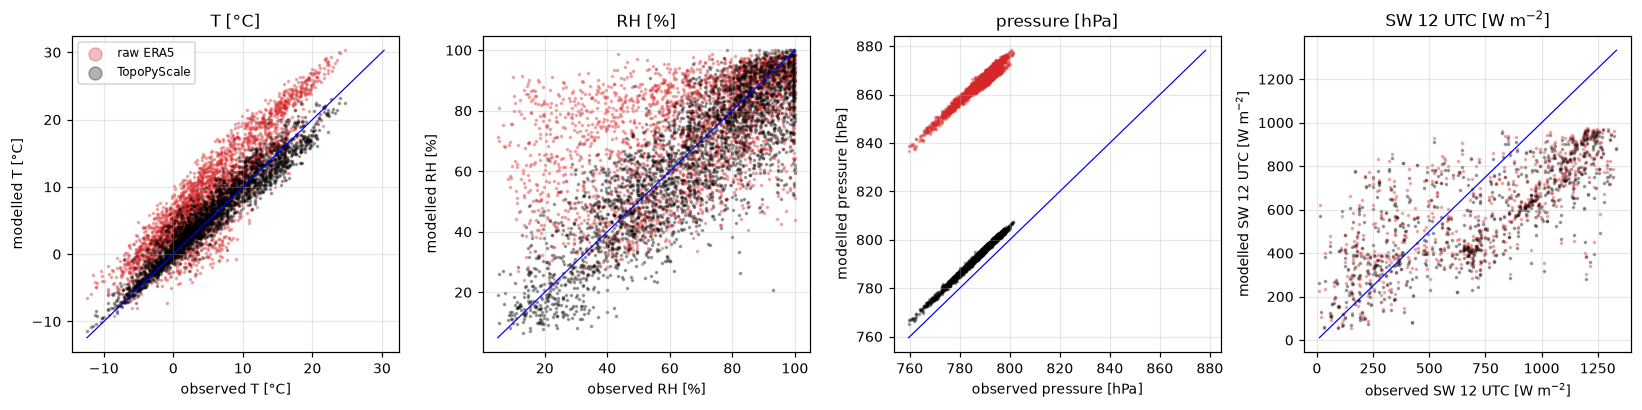

In [26]:
fig, axs = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, var, lab in zip(axs, ["T", "RH", "P", "SW"], ["T [°C]", "RH [%]", "pressure [hPa]", "SW 12 UTC [W m$^{-2}$]"]):
    sel = day if var == "SW" else np.ones(len(mtimes), bool)
    vt = "SW_horiz" if var == "SW" else var
    o = obs[var][sel]
    ax.scatter(o, era[var][sel], s=2, alpha=0.3, color="tab:red", label="raw ERA5")
    ax.scatter(o, tps[vt][sel], s=2, alpha=0.3, color="k", label="TopoPyScale")
    lim = [np.nanmin([o.min(), era[var][sel].min(), tps[vt][sel].min()]), np.nanmax([o.max(), era[var][sel].max(), tps[vt][sel].max()])]
    ax.plot(lim, lim, "b-", lw=0.8)
    ax.set(xlabel=f"observed {lab}", ylabel=f"modelled {lab}", title=lab)
axs[0].legend(markerscale=6, fontsize=8)
plt.tight_layout()
plt.show()

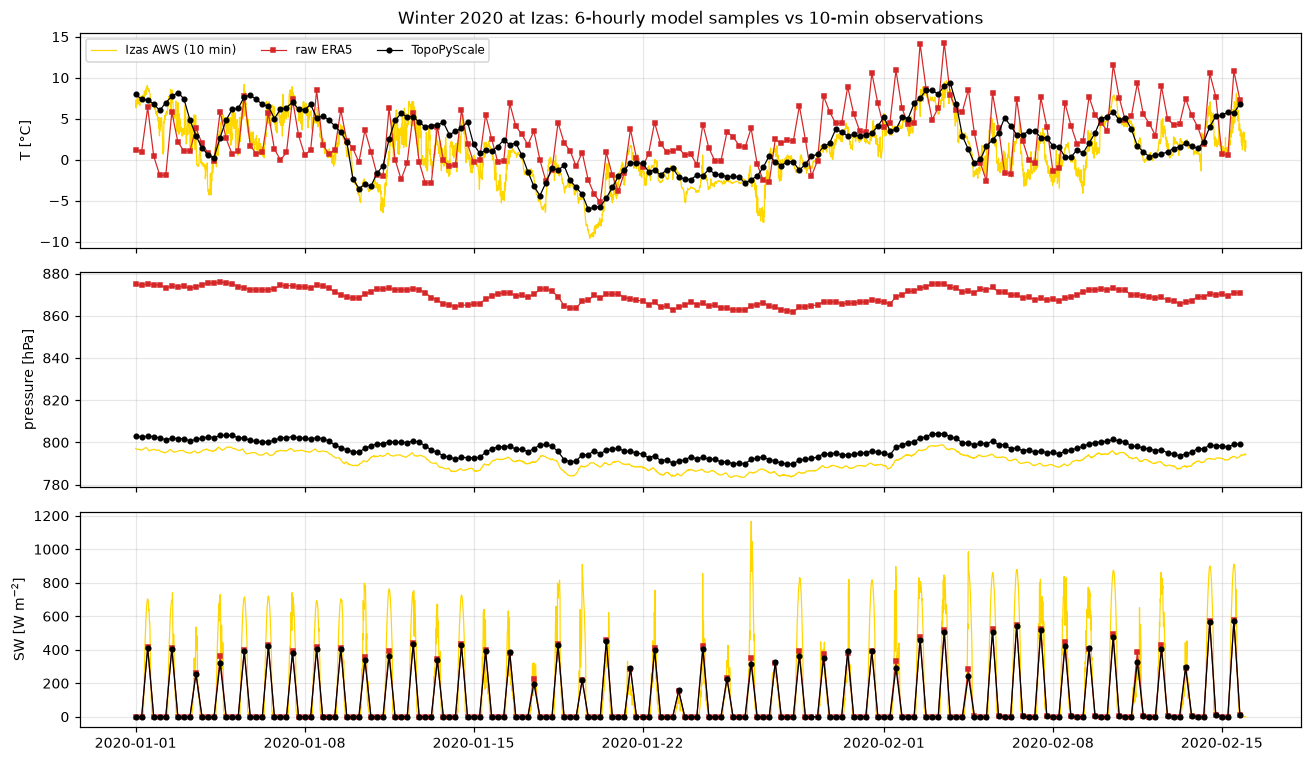

In [27]:
win_ = slice("2020-01-01", "2020-02-15")
fig, axs = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
for ax, var, lab in zip(axs, ["T", "P", "SW"], ["T [°C]", "pressure [hPa]", "SW [W m$^{-2}$]"]):
    ax.plot(obs10.loc[win_].index, obs10.loc[win_, var], color="gold", lw=0.8, label="Izas AWS (10 min)")
    ax.plot(era.loc[win_].index, era.loc[win_, var], "s-", color="tab:red", ms=3, lw=0.8, label="raw ERA5")
    ax.plot(tps.loc[win_].index, tps.loc[win_, "SW_horiz" if var == "SW" else var], "o-", color="k", ms=3, lw=0.8,
            label="TopoPyScale")
    ax.set_ylabel(lab)
axs[0].legend(fontsize=8, ncol=3)
axs[0].set_title("Winter 2020 at Izas: 6-hourly model samples vs 10-min observations")
plt.tight_layout()
plt.show()

### Precipitation

Monthly totals. The Geonor gauge undercatches snow at a windy site, and the models only have 4 one-hour samples per
day (scaled to 6 h), so we compare monthly totals rather than individual time steps.

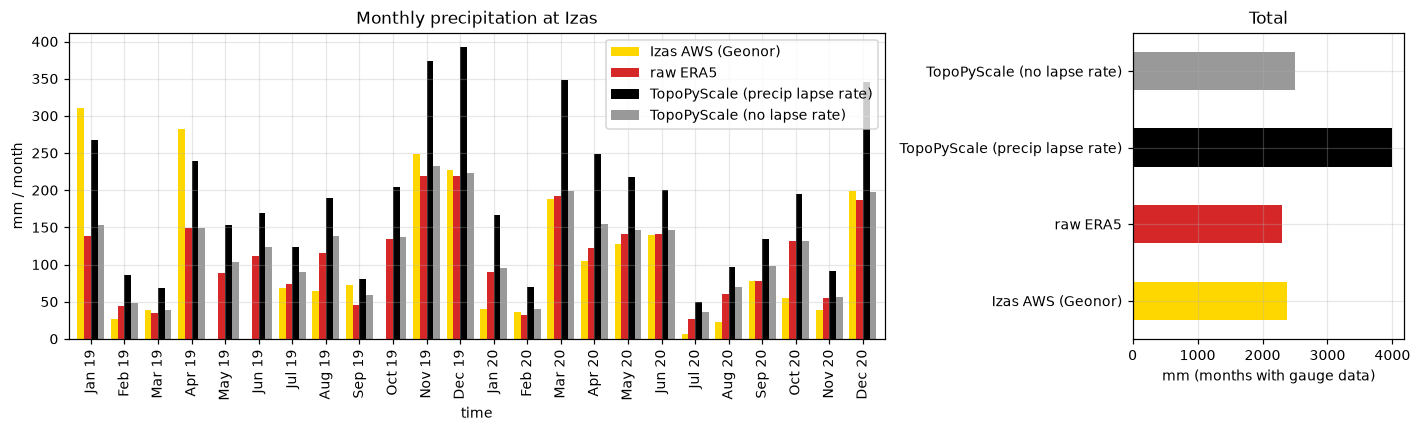

In [28]:
pr10 = pu.izas_precip(obs10)
mon = pd.DataFrame({
    "Izas AWS (Geonor)": pr10.resample("MS").sum(min_count=144 * 20),
    "raw ERA5": era["tp"].resample("MS").sum(),
    "TopoPyScale (precip lapse rate)": tps["tp"].resample("MS").sum(),
    "TopoPyScale (no lapse rate)": tps["tp_nolapse"].resample("MS").sum(),
}).loc["2019":"2020"]
fig, axs = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [3, 1]})
mon.plot.bar(ax=axs[0], width=0.8, color=["gold", "tab:red", "k", "0.6"])
axs[0].set_xticklabels([d.strftime("%b %y") for d in mon.index], rotation=90)
axs[0].set(ylabel="mm / month", title="Monthly precipitation at Izas")
mon.dropna().sum().plot.barh(ax=axs[1], color=["gold", "tab:red", "k", "0.6"])
axs[1].set(xlabel="mm (months with gauge data)", title="Total")
plt.tight_layout()
plt.show()

## 9. Snow: FSM driven by the downscaled forcing

TopoPyScale exports forcing for the Factorial Snow Model (FSM, Essery 2015). The exporter and the FSM namelist use
the **6-hourly time step** of the forcing (`dt = 21600 s`); outputs are daily means (`nave = 4`).
The simulation starts snow-free on 1 Jan 2019 while the station already had snow, so the **2019–20 season** is the
fair comparison.

---> FSM export with a timestep of 21600 s
---> File outputs/FSM_pt_00.txt saved
---> File outputs/FSM_pt_01.txt saved
---> File outputs/FSM_pt_02.txt saved


---> File outputs/FSM_pt_03.txt saved
---> File outputs/FSM_pt_04.txt saved
---> File outputs/FSM_pt_05.txt saved
---> File outputs/FSM_pt_06.txt saved
---> File outputs/FSM_pt_07.txt saved


---> File outputs/FSM_pt_08.txt saved
---> File outputs/FSM_pt_09.txt saved
---> File outputs/FSM_pt_10.txt saved
---> File outputs/FSM_pt_11.txt saved


---> File outputs/FSM_pt_12.txt saved
---> File outputs/FSM_pt_13.txt saved
---> File outputs/FSM_pt_14.txt saved
---> File outputs/FSM_pt_15.txt saved


---> File outputs/FSM_pt_16.txt saved
---> Run FSM simulation in parallel
---> FSM timestep: 21600 s, output averaged over 4 timesteps


nlst files ready


... (3 outputs left out)

---> File outputs/FSMnl_pt_09.txt saved
---> File outputs/FSMnl_pt_10.txt saved
---> File outputs/FSMnl_pt_11.txt saved
---> File outputs/FSMnl_pt_12.txt saved


---> File outputs/FSMnl_pt_13.txt saved
---> File outputs/FSMnl_pt_14.txt saved
---> File outputs/FSMnl_pt_15.txt saved


---> File outputs/FSMnl_pt_16.txt saved
---> Run FSM simulation in parallel
---> FSM timestep: 21600 s, output averaged over 4 timesteps
nlst files ready


Simulation done: fsm_sims/nlst_FSMnl_pt_12.txt
Simulation done: fsm_sims/nlst_FSMnl_pt_09.txt
Simulation done: fsm_sims/nlst_FSMnl_pt_15.txt
Simulation done: fsm_sims/nlst_FSMnl_pt_16.txt
Simulation done: fsm_sims/nlst_FSMnl_pt_01.txt
Simulation done: fsm_sims/nlst_FSMnl_pt_06.txt
Simulation done: fsm_sims/nlst_FSMnl_pt_07.txt
Simulation done: fsm_sims/nlst_FSMnl_pt_04.txt
Simulation done: fsm_sims/nlst_FSMnl_pt_00.txt
Simulation done: fsm_sims/nlst_FSMnl_pt_02.txt
Simulation done: fsm_sims/nlst_FSMnl_pt_05.txt
Simulation done: fsm_sims/nlst_FSMnl_pt_03.txt
Simulation done: fsm_sims/nlst_FSMnl_pt_10.txt
Simulation done: fsm_sims/nlst_FSMnl_pt_11.txt
Simulation done: fsm_sims/nlst_FSMnl_pt_14.txt
Simulation done: fsm_sims/nlst_FSMnl_pt_13.txt
Simulation done: fsm_sims/nlst_FSMnl_pt_08.txt
---> FSM simulations finished.
---> Removing FSM simulation config file
[FSM: Izas points] 0.1 min


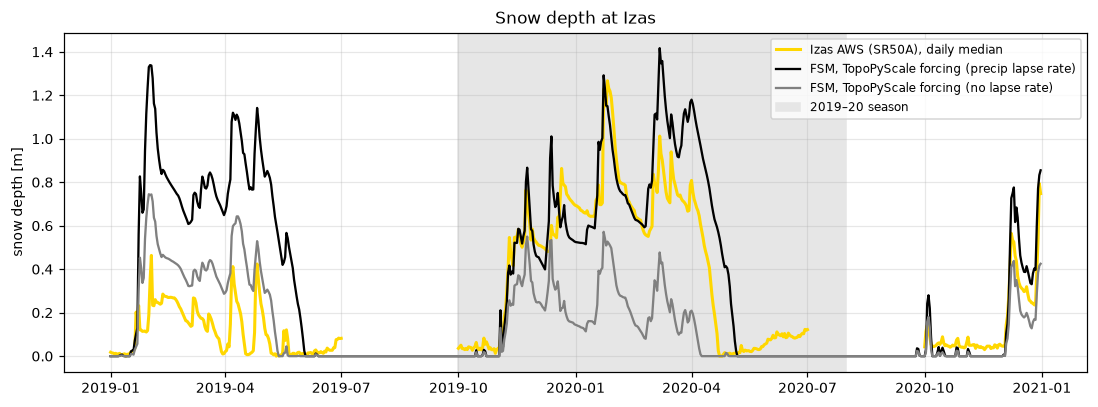

2019-20, FSM (lapse rate   ): {'bias': 0.06, 'RMSE': 0.2, 'r': 0.89, 'n': 275.0}, peak 1.42 m vs obs 1.27 m
2019-20, FSM (no lapse rate): {'bias': -0.28, 'RMSE': 0.37, 'r': 0.82, 'n': 275.0}, peak 0.57 m vs obs 1.27 m


In [29]:
if RUN_FSM:
    with timed("FSM: Izas points"):
        snd_i, swe_i = pu.run_fsm(mp_i, FSM_EXEC, ds=dsi, tag="FSM", n_core=CPU_CORES)
        ds_nl = dsi.copy()
        ds_nl["tp"] = dsi.tp / dsi.precip_lapse_rate
        snd_inl, _ = pu.run_fsm(mp_i, FSM_EXEC, ds=ds_nl, tag="FSMnl", n_core=CPU_CORES)
hs_obs = pu.izas_snow_depth(obs10)
day_idx = lambda da: da.assign_coords(time=da.time.to_index().normalize())
snd_i, snd_inl = day_idx(snd_i), day_idx(snd_inl)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(hs_obs.loc["2019":"2020"].index, hs_obs.loc["2019":"2020"], color="gold", lw=2, label="Izas AWS (SR50A), daily median")
ax.plot(snd_i.time, snd_i.sel(point_name="Izas_AWS"), "k", label="FSM, TopoPyScale forcing (precip lapse rate)")
ax.plot(snd_inl.time, snd_inl.sel(point_name="Izas_AWS"), color="0.5", label="FSM, TopoPyScale forcing (no lapse rate)")
ax.axvspan(pd.Timestamp("2019-10-01"), pd.Timestamp("2020-07-31"), color="0.9", zorder=0, label="2019–20 season")
ax.set(ylabel="snow depth [m]", title="Snow depth at Izas")
ax.legend(fontsize=8)
plt.show()

s1920 = slice("2019-10-01", "2020-07-31")
hs_s = hs_obs.loc[s1920]
for lab, da in (("lapse rate", snd_i), ("no lapse rate", snd_inl)):
    m = da.sel(point_name="Izas_AWS").to_series().loc[s1920]
    print(f"2019-20, FSM ({lab:13s}): {pu.metrics(hs_s, m).round(2).to_dict()}, "
          f"peak {m.max():.2f} m vs obs {hs_s.max():.2f} m")

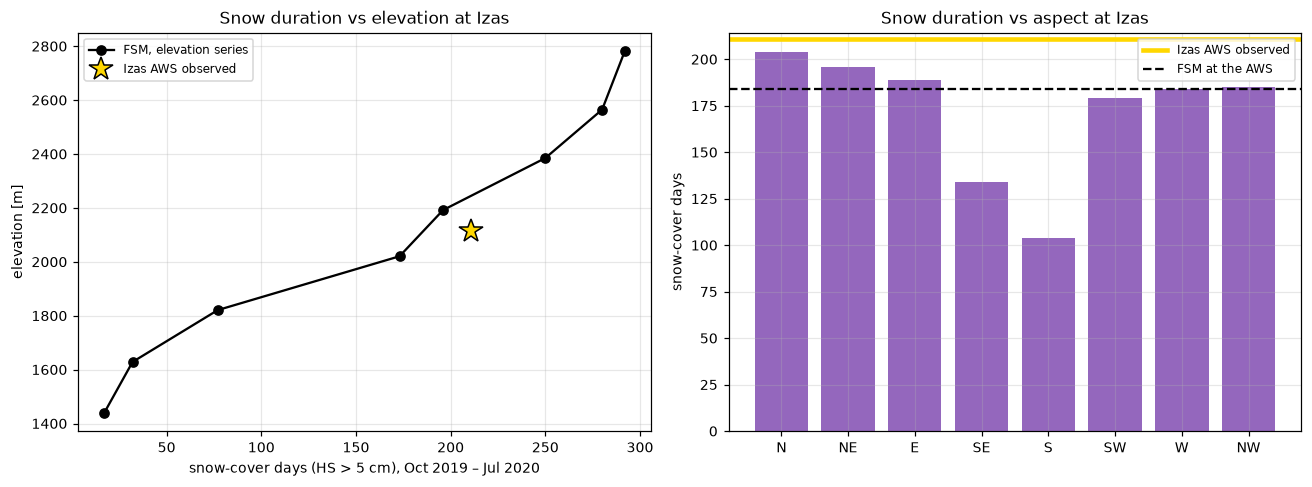

In [30]:
scd = lambda da: (da.sel(time=s1920) > 0.05).sum("time").to_series()   # snow-cover days, 2019-20
scd_obs = int((hs_s > 0.05).sum())
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
es_scd = scd(snd_i).reindex(es.index)
axs[0].plot(es_scd, es.elevation, "-o", color="k", label="FSM, elevation series")
axs[0].plot(scd_obs, pu.IZAS["elev"], "*", color="gold", mec="k", ms=16, label="Izas AWS observed")
axs[0].set(xlabel="snow-cover days (HS > 5 cm), Oct 2019 – Jul 2020", ylabel="elevation [m]",
           title="Snow duration vs elevation at Izas")
axs[0].legend(fontsize=8)
r_scd = scd(snd_i).reindex(rose.index)
axs[1].bar(np.arange(len(rose)), r_scd, color="tab:purple")
axs[1].axhline(scd_obs, color="gold", lw=3, label="Izas AWS observed")
axs[1].axhline(scd(snd_i)["Izas_AWS"], color="k", ls="--", label="FSM at the AWS")
axs[1].set(xticks=np.arange(len(rose)), xticklabels=[n.split("_")[-1] for n in rose.index],
           title="Snow duration vs aspect at Izas", ylabel="snow-cover days")
axs[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

### Snow along the whole transect

FSM is cheap: we run it for every cluster and map the snow-cover duration of the 2019–20 season.

---> FSM export with a timestep of 21600 s
---> File outputs/FSM_pt_000.txt saved
---> File outputs/FSM_pt_001.txt saved


---> File outputs/FSM_pt_002.txt saved
---> File outputs/FSM_pt_003.txt saved
---> File outputs/FSM_pt_004.txt saved
---> File outputs/FSM_pt_005.txt saved


---> File outputs/FSM_pt_006.txt saved
---> File outputs/FSM_pt_007.txt saved
---> File outputs/FSM_pt_008.txt saved


---> File outputs/FSM_pt_009.txt saved
---> File outputs/FSM_pt_010.txt saved
---> File outputs/FSM_pt_011.txt saved
---> File outputs/FSM_pt_012.txt saved


---> File outputs/FSM_pt_013.txt saved
---> File outputs/FSM_pt_014.txt saved
---> File outputs/FSM_pt_015.txt saved
---> File outputs/FSM_pt_016.txt saved


---> File outputs/FSM_pt_017.txt saved
---> File outputs/FSM_pt_018.txt saved
---> File outputs/FSM_pt_019.txt saved
---> File outputs/FSM_pt_020.txt saved


... (68 outputs left out)

---> File outputs/FSM_pt_298.txt saved
---> File outputs/FSM_pt_299.txt saved
---> Run FSM simulation in parallel
---> FSM timestep: 21600 s, output averaged over 4 timesteps


nlst files ready


Simulation done: fsm_sims/nlst_FSM_pt_122.txt
Simulation done: fsm_sims/nlst_FSM_pt_066.txt
Simulation done: fsm_sims/nlst_FSM_pt_146.txt
Simulation done: fsm_sims/nlst_FSM_pt_001.txt
Simulation done: fsm_sims/nlst_FSM_pt_139.txt
Simulation done: fsm_sims/nlst_FSM_pt_240.txt
Simulation done: fsm_sims/nlst_FSM_pt_065.txt
Simulation done: fsm_sims/nlst_FSM_pt_298.txt
Simulation done: fsm_sims/nlst_FSM_pt_073.txt
Simulation done: fsm_sims/nlst_FSM_pt_189.txt
Simulation done: fsm_sims/nlst_FSM_pt_280.txt
Simulation done: fsm_sims/nlst_FSM_pt_245.txt
Simulation done: fsm_sims/nlst_FSM_pt_283.txt
Simulation done: fsm_sims/nlst_FSM_pt_231.txt
Simulation done: fsm_sims/nlst_FSM_pt_269.txt
Simulation done: fsm_sims/nlst_FSM_pt_029.txt
Simulation done: fsm_sims/nlst_FSM_pt_184.txt
Simulation done: fsm_sims/nlst_FSM_pt_258.txt
Simulation done: fsm_sims/nlst_FSM_pt_250.txt
Simulation done: fsm_sims/nlst_FSM_pt_205.txt
Simulation done: fsm_sims/nlst_FSM_pt_138.txt
Simulation done: fsm_sims/nlst_FSM

[FSM: transect clusters] 0.4 min


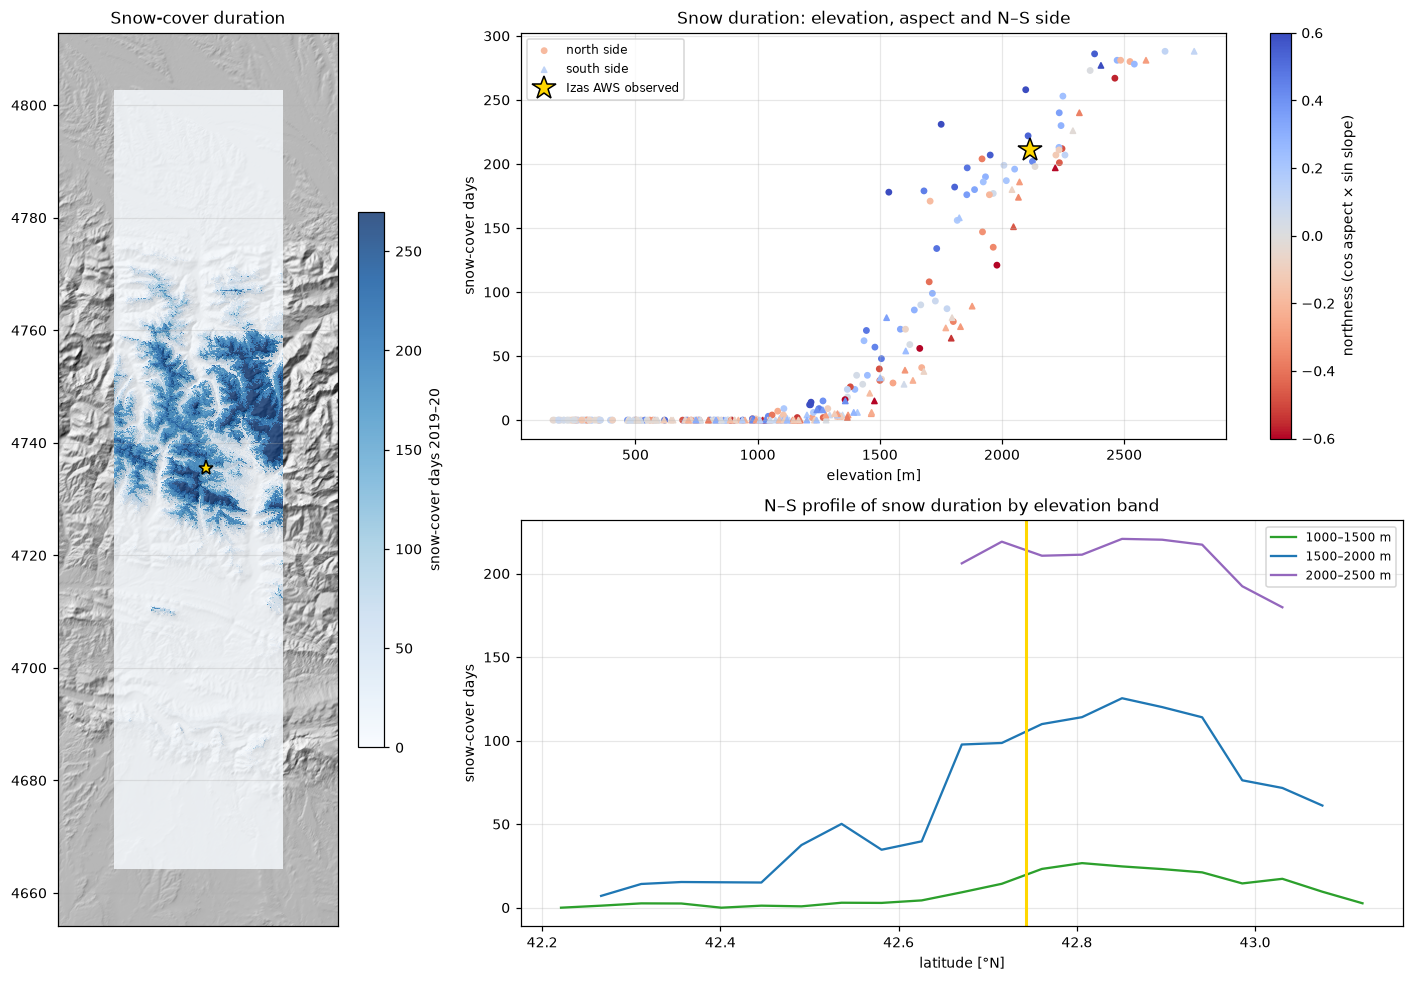

In [31]:
if RUN_FSM:
    with timed("FSM: transect clusters"):
        snd_t, swe_t = pu.run_fsm(mp, FSM_EXEC, ds=down, tag="FSM", n_core=CPU_CORES)
snd_t = day_idx(snd_t)
clus["SCD"] = scd(snd_t)
fig = plt.figure(figsize=(13, 9))
ax0 = fig.add_subplot(1, 3, 1)
show(ax0, clus.SCD, "Blues", "snow-cover days 2019–20", vmin=0, vmax=270)
ax0.set_title("Snow-cover duration")
ax1 = fig.add_subplot(2, 3, (2, 3))
for side, c in (("north", "tab:blue"), ("south", "tab:orange")):
    s_ = clus[clus.side == side]
    sc = ax1.scatter(s_.elevation, s_.SCD, s=12, c=s_.northness, cmap="coolwarm_r", vmin=-0.6, vmax=0.6,
                     marker="o" if side == "north" else "^", label=f"{side} side")
ax1.plot(pu.IZAS["elev"], scd_obs, "*", color="gold", mec="k", ms=16, label="Izas AWS observed")
plt.colorbar(sc, ax=ax1, label="northness (cos aspect × sin slope)")
ax1.set(xlabel="elevation [m]", ylabel="snow-cover days", title="Snow duration: elevation, aspect and N–S side")
ax1.legend(fontsize=8)
ax2 = fig.add_subplot(2, 3, (5, 6))
for lo_, hi_, c in ((1000, 1500, "tab:green"), (1500, 2000, "tab:blue"), (2000, 2500, "tab:purple")):
    W_ = pu.lat_weights(ds_param, bin_km=5, by=(elev_px > lo_) & (elev_px < hi_))
    p_ = pu.profile(W_, clus.SCD)
    ax2.plot(p_.index, p_, color=c, label=f"{lo_}–{hi_} m")
ax2.axvline(pu.IZAS["lat"], color="gold", lw=2)
ax2.set(xlabel="latitude [°N]", ylabel="snow-cover days", title="N–S profile of snow duration by elevation band")
ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 10. Summary

**What TopoPyScale adds to ERA5 here**

* **Elevation.** ERA5's Pyrenees peak at ~1400 m, while the real summits along the transect reach ~3000 m.
  TopoPyScale brings temperature, humidity and pressure to the real elevation of every slope. At Izas (2113 m,
  ~700 m above its ERA5 cell) the temperature bias drops from +3.5 °C to +0.4 °C (RMSE 4.9 → 1.9 °C), the pressure
  bias from +77 hPa to +6 hPa (mostly the DEM pixel being ~40 m below the station), and the RH correlation rises
  from 0.53 to 0.86. The observed temperatures fall on the downscaled elevation profile.
* **N–S climate.** The large-scale contrast of ERA5 (wetter and cloudier Atlantic side, sunnier south) is kept and
  combined with the local topography; at the same elevation the northern slopes are wetter and get less noon sun.
* **Terrain and radiation.** Aspect, slope, cast shadows and sky view turn one ERA5 value into strongly contrasting
  radiation: at the station elevation, winter-noon SW is ~550 W m⁻² on south slopes and ~190 W m⁻² on north
  slopes. With FSM, this gives ~105 vs ~205 snow-cover days in 2019–20 on south vs north slopes around Izas.
* **Snow.** Driven by the downscaled forcing (with the precipitation lapse rate), FSM reproduces the 2019–20
  snow season at Izas: peak 1.42 m vs 1.27 m observed, RMSE 0.20 m. Without the lapse rate the snowpack is far too
  thin, although the gauge (which undercatches snow) is closer to the precipitation without lapse rate.
* **Cheap.** TopoSUB turns 4.6 million 30 m pixels into 300 clusters; with ERA5 in zarr the downscaling takes
  ~1 min and FSM on all clusters well under a minute. The terrain analysis of the 30 m DEM (sky view, horizons)
  is the expensive step, done once.

**Limitations to keep in mind**

* 6-hourly forcing: radiation and precipitation are 1-hour samples at 00/06/12/18 UTC; daily totals are estimates.
  ERA5's own noon SW is too low at Izas (cloudiness), and TopoPyScale inherits it.
* Wind is the free-atmosphere wind at the point elevation (no terrain sheltering/speed-up): +2.7 m s⁻¹ at Izas.
* No terrain-reflected shortwave, and the direct beam is not corrected for elevation.
* The precipitation lapse rate is a simple monthly factor; compare both variants against the gauge and the snow.

In [32]:
pd.Series(TIMES).div(60).round(2).rename("minutes").to_frame()

,minutes
download + ERA5 preparation,0.02
DEM preparation,0.01
transect: DEM parameters,1.06
transect: clustering,0.00
transect: solar geometry,0.00
transect: horizons,0.05
transect: downscaling,0.49
Izas: DEM parameters,0.01
"Izas: points, solar, horizons, downscaling",0.02
FSM: Izas points,0.12
